# ADY201m — AI, DATA SCIENCE WITH PYTHON & SQL
## REPORT 1 — ONGOING ASSESSMENT 1
**Nội dung:** Xác định bài toán, thu thập và làm sạch dữ liệu.

### PROJECT INFORMATION
- **Tên đề tài:** Phân loại nhãn tiền tiểu đường/tiểu đường ở người tham gia khảo sát BRFSS2015 từ 30–59 tuổi bằng học máy.
- **Mã lớp:** AI2104 — **Nhóm 6**

| Họ và tên | Mã sinh viên | Vai trò trong nhóm |
|---|---|---|
| Trần Tuấn Hiệp | HE211144 | 1.1, 1.2, 1.3, 2.1 |
| Nguyễn Thế Hải | HE211655 | 2.2, 3.1, 3.2, 3.3 |
| Trần Công Du | HE211007 | 3.4, 3.5, 4.1 |

- **Nguồn:** CDC BRFSS2015, `LLCP2015XPT.zip`; xuất CSV nguồn `2015.csv`.
- **Đối tượng:** Người tham gia 30–59 tuổi (`_AGEG5YR` mã 3–8), bất kể tình trạng việc làm; loại hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`).
- **Đầu ra:** Giữ 21 feature và một nhãn `Diabetes_binary`: 0 = mã nguồn 3; 1 = mã nguồn 1 hoặc 4.
- **Mục đích:** Nghiên cứu học thuật trên mẫu khảo sát; không dự đoán phát bệnh trong tương lai.
- **Ongoing 1:** Giữ cách xử lý NaN/mã khảo sát, BMI, kiểu dữ liệu, outlier và duplicate của bản trước. Các kết quả bên dưới được tính lại cho phạm vi mới.
- **Nguồn tham khảo bộ biến:** [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).
- **Ngày nộp:**


## GRADING RUBRIC

*Phần này dành cho giảng viên chấm điểm và nhận xét.*

| Tiêu chí | Nội dung đánh giá | Điểm tối đa | Điểm đạt được | Nhận xét của giảng viên |
| :--- | :--- | :---: | :---: | :--- |
| **1. Hiểu bài toán** | Bối cảnh, câu hỏi và mục tiêu khoa học dữ liệu rõ ràng, thực tế. | **2,5** | | |
| **2. Thu thập và kiểm tra dữ liệu** | Mô tả chính xác nguồn dữ liệu, bảng mô tả biến, đọc dữ liệu và kiểm tra cấu trúc. | **2,5** | | |
| **3. Làm sạch và tiền xử lý** | Code xử lý missing, duplicate, kiểu dữ liệu, outlier; giải thích lựa chọn phương pháp. | **4,0** | | |
| **4. Thảo luận và kết luận** | Đánh giá mức độ sẵn sàng, bảng trước/sau làm sạch và kế hoạch tiếp theo hợp lý. | **1,0** | | |
| **TỔNG** | **Đánh giá tổng thể báo cáo giai đoạn 1** | **10,0** | | |

---


# PART 1: BUSINESS UNDERSTANDING [2.5 POINTS]

### Key Guidelines:
1. **Bối cảnh:** Vấn đề thực tế xuất phát từ đâu? Tổ chức hoặc đối tượng sử dụng đang gặp vấn đề gì?
2. **Câu hỏi:** Nêu 2–3 câu hỏi chính cần trả lời để hỗ trợ quyết định.
3. **Bài toán khoa học dữ liệu:** Xác định loại bài toán và biến mục tiêu.

---


#### STUDENT TASK 1.1: BUSINESS CONTEXT & PROJECT JUSTIFICATION

**Bối cảnh:** Dữ liệu khảo sát sức khỏe ghi nhận nhiều thông tin về thể trạng, hành vi, tình trạng sức khỏe và điều kiện tiếp cận chăm sóc y tế. Một vấn đề cần nghiên cứu là những thông tin này có thể hỗ trợ phân biệt nhóm người tự khai từng được thông báo mắc tiền tiểu đường/tiểu đường với nhóm trả lời không mắc tiểu đường đến mức nào.

**Vấn đề nghiên cứu:** Nhóm sử dụng BRFSS2015 để đánh giá khả năng phân loại nhãn khảo sát bằng học máy. Việc nghiên cứu bao gồm tìm hiểu các đặc điểm liên quan đến nhãn và so sánh hiệu quả của các mô hình trên cùng phạm vi dữ liệu.

**Lý do chọn nhóm tuổi 30–59:** Nhóm giới hạn độ tuổi để xác định đối tượng nghiên cứu rõ ràng và tập trung phân tích trong phạm vi môn học. Sự quan tâm đến sức khỏe ở những người có nhiều trách nhiệm công việc và cuộc sống là động cơ lựa chọn đề tài; đây chưa phải đặc điểm đã được kiểm chứng của toàn bộ nhóm tuổi. Nghiên cứu bao gồm mọi người tham gia đáp ứng điều kiện tuổi, bất kể tình trạng việc làm. Việc thu hẹp tuổi chưa bảo đảm mô hình sẽ đạt hiệu quả tốt hơn.

**Đối tượng sử dụng và quyết định được hỗ trợ:** Kết quả phục vụ nhóm nghiên cứu và giảng viên, giúp đánh giá mức độ phù hợp của dữ liệu khảo sát đối với bài toán phân loại, lựa chọn mô hình và xác định những đặc điểm cần phân tích tiếp.

**Phạm vi và giới hạn:** Nghiên cứu loại hồ sơ chỉ tiểu đường khi mang thai; nhãn dương gộp tiền tiểu đường và tiểu đường. Kết quả phản ánh khả năng phân loại nhãn tự khai trong mẫu sau làm sạch, không dự đoán phát bệnh trong tương lai hoặc chứng minh quan hệ nhân quả.

**Tham khảo bối cảnh:** [Xie và cộng sự, CDC 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm), dùng BRFSS2014 và định nghĩa nhãn/quần thể khác; không dùng kết quả đó thay cho đánh giá của nhóm.


#### STUDENT TASK 1.2: CORE RESEARCH QUESTIONS

1. **Những đặc điểm sức khỏe, hành vi và nhân khẩu học nào có liên quan đến nhãn tiền tiểu đường/tiểu đường trong mẫu người tham gia 30–59 tuổi?**  
   Kết quả hỗ trợ xác định các đặc điểm cần phân tích sâu hơn.

2. **Các mô hình học máy phân loại nhãn này hiệu quả đến đâu dựa trên 21 đặc trưng khảo sát?**  
   Đánh giá bằng Accuracy, Precision, Recall, F1-score và ROC-AUC để nhận diện khả năng và giới hạn của mô hình.

3. **Trong các mô hình thử nghiệm, mô hình nào phù hợp nhất với mục tiêu nghiên cứu khi xem xét đồng thời các chỉ số đánh giá?**  
   Kết quả hỗ trợ lựa chọn mô hình cho giai đoạn nghiên cứu tiếp theo.

Ongoing 1 chuẩn bị dữ liệu để trả lời các câu hỏi trên ở ongoing 2; chưa đưa ra kết luận về hiệu năng mô hình.


#### STUDENT TASK 1.3: DATA SCIENCE PROBLEM FORMULATION

- **Loại bài toán:** Học có giám sát, phân loại nhị phân trong phạm vi học thuật.
- **Đơn vị phân tích:** Một bản ghi khảo sát đáp ứng tuổi 30–59, không có `DIABETE3=2`, sau đó qua các quy tắc làm sạch hiện tại. Không yêu cầu đang có việc làm.
- **Biến mục tiêu:** `Diabetes_binary`: 0 nếu `DIABETE3=3`; 1 nếu `DIABETE3=1 hoặc 4`. Loại toàn bộ hồ sơ chỉ tiểu đường khi mang thai (`DIABETE3=2`) trước khi gộp nhãn; không chuyển các hồ sơ đó sang lớp 0. NaN và mã 7/9 được xử lý theo quy trình làm sạch.
- **Đầu vào:** Giữ đủ 21 feature, bao gồm `Age` dạng mã 3–8 (30–34 đến 55–59 tuổi); chưa chọn/bỏ feature ở ongoing 1.
- **Đánh giá ở giai đoạn sau:** So sánh mô hình bằng Accuracy, Precision, Recall, F1-score và ROC-AUC. Theo dõi cả hai lớp và phân bố nhãn; chưa chốt ngưỡng hoặc khẳng định mô hình nào tốt nhất.
- **Diễn giải:** Phân loại nhãn khảo sát; không dự đoán thời điểm hay xác suất mắc bệnh trong tương lai và không suy rộng cho dân số.


# PART 2: DATA COLLECTION & INITIAL DATA UNDERSTANDING [2.5 POINTS]

### DATA SOURCE & COLLECTION METHOD

Nhóm sử dụng SAS Transport (XPT) trong `LLCP2015XPT.zip` của CDC, xuất toàn bộ thành `2015.csv` và đọc CSV để kiểm tra. Nhóm không trực tiếp thu thập khảo sát. Kích thước nguồn và số dòng ở mỗi bước được in từ dữ liệu thực tế.

Chọn 21 feature và một biến mục tiêu theo bộ biến của Alex Teboul. Trước xử lý missing, nhóm chọn `_AGEG5YR` mã 3–8, sau đó loại `DIABETE3=2`. Đây là chọn phạm vi nghiên cứu, được ghi riêng với số dòng mất do làm sạch. Không lọc theo giới tính hoặc việc làm.

`df_selected_all`: 22 cột trên toàn bộ nguồn; `df_age_raw`: nhóm 30–59 trước loại mã 2; `df_selected_raw`: mẫu nghiên cứu sau hai điều kiện phạm vi, trước xử lý NaN/mã khảo sát. Các biểu đồ trước/sau làm sạch đều dùng mẫu nghiên cứu này làm điểm bắt đầu.

Giữ quy tắc xóa dòng thiếu, chuyển mã, BMI chia 100/làm tròn và kiểm tra kiểu. `df_clean` giữ duplicate; `df_no_duplicates` là bản đối chiếu. Cả hai có 22 cột.

**Nguồn:** [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html), [codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), [bộ biến tham khảo](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset).


#### STUDENT TASK 2.1: DATA DICTIONARY

Bảng dưới đây mô tả 22 biến được chọn từ dữ liệu nguồn `2015.csv`, gồm tên cột nguồn, tên cột sau xử lý, kiểu dữ liệu ban đầu và ý nghĩa đầu ra. Các cột nguồn được đọc bằng pandas với kiểu `float64`. Giá trị ví dụ trong bảng là giá trị sau chuyển mã và xử lý BMI.

| STT | Tên cột nguồn | Tên cột sau xử lý | Kiểu dữ liệu ban đầu | Loại biến | Ý nghĩa và mã hóa sau xử lý | Giá trị ví dụ sau xử lý |
| :---: | :--- | :--- | :---: | :--- | :--- | :---: |
| 1 | `DIABETE3` | `Diabetes_binary` | float64 | Phân loại nhị phân — mục tiêu | 0: không tiểu đường (DIABETE3=3); 1: tiểu đường hoặc tiền tiểu đường/borderline (DIABETE3=1,4); loại hồ sơ DIABETE3=2 | 0.0 |
| 2 | `_RFHYPE5` | `HighBP` | float64 | Phân loại nhị phân | Huyết áp cao; 0: không, 1: có | 1.0 |
| 3 | `TOLDHI2` | `HighChol` | float64 | Phân loại nhị phân | Cholesterol cao; 0: không, 1: có | 1.0 |
| 4 | `_CHOLCHK` | `CholCheck` | float64 | Phân loại nhị phân | Đã kiểm tra cholesterol trong 5 năm qua; 0: không, 1: có | 1.0 |
| 5 | `_BMI5` | `BMI` | float64 | Số — chỉ số định lượng | Chỉ số khối cơ thể (kg/m²); chuyển từ `_BMI5` bằng cách chia 100 và làm tròn đến số nguyên | 40.0 |
| 6 | `SMOKE100` | `Smoker` | float64 | Phân loại nhị phân | Đã hút ít nhất 100 điếu thuốc trong đời; 0: không, 1: có | 1.0 |
| 7 | `CVDSTRK3` | `Stroke` | float64 | Phân loại nhị phân | Từng được thông báo bị đột quỵ; 0: không, 1: có | 0.0 |
| 8 | `_MICHD` | `HeartDiseaseorAttack` | float64 | Phân loại nhị phân | Tiền sử bệnh mạch vành hoặc nhồi máu cơ tim; 0: không, 1: có | 0.0 |
| 9 | `_TOTINDA` | `PhysActivity` | float64 | Phân loại nhị phân | Có hoạt động thể chất ngoài công việc trong 30 ngày qua; 0: không, 1: có | 0.0 |
| 10 | `_FRTLT1` | `Fruits` | float64 | Phân loại nhị phân | Tần suất tiêu thụ trái cây bao gồm nước ép trái cây 100% theo biến tính toán CDC; 0: dưới 1 lần/ngày; 1: từ 1 lần/ngày trở lên | 0.0 |
| 11 | `_VEGLT1` | `Veggies` | float64 | Phân loại nhị phân | Tần suất tiêu thụ rau theo các nhóm thực phẩm trong khảo sát; 0: dưới 1 lần/ngày; 1: từ 1 lần/ngày trở lên | 1.0 |
| 12 | `_RFDRHV5` | `HvyAlcoholConsump` | float64 | Phân loại nhị phân | Uống rượu bia mức cao theo tiêu chí khảo sát (nam trên 14, nữ trên 7 đơn vị uống mỗi tuần); 0: không, 1: có | 0.0 |
| 13 | `HLTHPLN1` | `AnyHealthcare` | float64 | Phân loại nhị phân | Có bảo hiểm hoặc hình thức chi trả chăm sóc sức khỏe; 0: không, 1: có | 1.0 |
| 14 | `MEDCOST` | `NoDocbcCost` | float64 | Phân loại nhị phân | Trong 12 tháng qua từng cần khám nhưng không thể do chi phí; 0: không, 1: có | 0.0 |
| 15 | `GENHLTH` | `GenHlth` | float64 | Phân loại thứ bậc | Tự đánh giá sức khỏe: 1 rất tốt (Excellent), 2 tốt hơn mức thông thường (Very good), 3 tốt (Good), 4 trung bình (Fair), 5 kém (Poor) | 5.0 |
| 16 | `MENTHLTH` | `MentHlth` | float64 | Số rời rạc | Số ngày sức khỏe tinh thần không tốt trong 30 ngày qua; 0–30 | 18.0 |
| 17 | `PHYSHLTH` | `PhysHlth` | float64 | Số rời rạc | Số ngày sức khỏe thể chất không tốt trong 30 ngày qua; 0–30 | 15.0 |
| 18 | `DIFFWALK` | `DiffWalk` | float64 | Phân loại nhị phân | Khó khăn nghiêm trọng khi đi bộ hoặc leo cầu thang; 0: không, 1: có | 1.0 |
| 19 | `SEX` | `Sex` | float64 | Phân loại nhị phân | Giới tính theo mã khảo sát: 0 nữ, 1 nam | 0.0 |
| 20 | `_AGEG5YR` | `Age` | float64 | Phân loại thứ bậc | Trong mẫu: mã 3–8 tương ứng 30–34, 35–39, 40–44, 45–49, 50–54, 55–59. Giữ mã gốc; không phải tuổi trực tiếp | 7 (50–54 tuổi) |
| 21 | `EDUCA` | `Education` | float64 | Phân loại thứ bậc | Mã trình độ học vấn 1–6: chưa đi học/mẫu giáo; lớp 1–8; lớp 9–11; tốt nghiệp trung học; học cao đẳng/đại học 1–3 năm; tốt nghiệp cao đẳng/đại học từ 4 năm | 4.0 |
| 22 | `INCOME2` | `Income` | float64 | Phân loại thứ bậc | Mã thu nhập hộ gia đình hàng năm, 1–8: dưới 10.000; 10.000–<15.000; 15.000–<20.000; 20.000–<25.000; 25.000–<35.000; 35.000–<50.000; 50.000–<75.000; từ 75.000 USD | 3.0 |

**Ghi chú về Fruits và Veggies:** Đây là tần suất tiêu thụ, không phải số khẩu phần. Giá trị 0 không có nghĩa là hoàn toàn không tiêu thụ.

**Nguồn mô tả:** [Diabetes Health Indicators Dataset trên Kaggle](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [tài liệu khảo sát BRFSS2015 của CDC](https://www.cdc.gov/brfss/annual_data/annual_2015.html). Cần phân biệt CSV nguồn `2015.csv` có 330 cột với CSV đầu ra 22 cột. Bảng này chỉ mô tả 22 biến được chọn, không phải từ điển toàn bộ CSV nguồn; tên cột sau xử lý và mã đầu ra do quy trình nhóm tạo ra.


### Căn cứ lựa chọn 21 biến đầu vào từ dữ liệu BRFSS2015

**Phạm vi lựa chọn:** Nhóm giữ **21 feature và một nhãn**, tạo 22 cột đầu ra. Đây là **bộ đặc trưng ứng viên ban đầu**, không phải kết quả tìm 21 biến tối ưu từ toàn bộ 330 cột. Bộ biến kế thừa Diabetes Health Indicators Dataset của Alex Teboul; ý nghĩa, câu hỏi và mã nguồn được đối chiếu BRFSS2015 Codebook. Nguồn quy trình không thay thế bằng chứng chuyên ngành.

**Ba lớp căn cứ:**

1. **Chuyên ngành và mục tiêu:** Xem xét tuổi, chuyển hóa, hành vi, sức khỏe tổng quát/bệnh đi kèm và điều kiện tiếp cận y tế. Nhãn là tình trạng đã được thông báo trong khảo sát, nên một số biến cung cấp tín hiệu về bệnh hiện tại hoặc khả năng được chẩn đoán; không phải mọi biến đều là nguy cơ có trước bệnh.
2. **Đo lường trong dữ liệu:** Biến phải có mặt trong CSV nguồn, có câu hỏi/mã giải thích được và phù hợp cách thu thập thông tin dự kiến. Đánh giá cả missing do câu hỏi bị bỏ qua, không chỉ NaN/mã từ chối.
3. **Kiểm chứng ở giai đoạn sau:** EDA, kiểm định phù hợp và CV trên Train sẽ xác định mức liên hệ/đóng góp dự đoán. Không dùng Test để chọn feature. Báo cáo giai đoạn 1 không trình bày kết quả mô hình giai đoạn 2 như bằng chứng đã có khi chọn ban đầu.

**Nghiên cứu liên quan và giới hạn chuyển giao**

| Nguồn | Căn cứ hỗ trợ | Giới hạn đối với nhóm |
|---|---|---|
| [Xie và cộng sự, 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Chọn biến BRFSS theo tài liệu, kết hợp sức khỏe, hành vi và nhân khẩu/xã hội | BRFSS2014, chọn 27 biến, loại người dưới 30 và tiền tiểu đường; không cùng bộ 21 hoặc nhãn gộp |
| [Nghiên cứu tối ưu bảng hỏi, 2024](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | BRFSS2021 có bộ 21 biến gần bộ của nhóm, khảo sát rút gọn câu hỏi | Khác năm và mã hóa; AlcoholConsump là lượng uống, không giống HvyAlcoholConsump nhị phân; không sao chép thứ hạng/hiệu năng |
| [Muhammad và cộng sự, 2025](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) | BRFSS2023 Tennessee hỗ trợ giá trị dự đoán của BMI, huyết áp, cholesterol và bối cảnh xã hội | Quần thể một bang, cách xếp tiền tiểu đường/tiểu đường thai kỳ khác nhóm |
| [Whitehall II, 2012](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Nghiên cứu dọc xét hành vi, BMI và dấu hiệu chuyển hóa cùng bất bình đẳng xã hội | Đo lường khác các câu hỏi nhị phân BRFSS; không xác nhận từng proxy có cùng tác dụng |
| [Agardh và cộng sự, 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) | Tổng quan/meta-analysis hỗ trợ xem xét thu nhập và học vấn | Liên hệ quần thể, không xác định đóng góp riêng trong mô hình nhóm |
| [Towne và cộng sự, 2017](https://pubmed.ncbi.nlm.nih.gov/28445431/) | BRFSS2011–2015 nghiên cứu chẩn đoán tự khai báo và bỏ khám do chi phí | Bằng chứng bối cảnh tiếp cận chăm sóc, không chứng minh nguyên nhân sinh học |

Nhiều bài kế thừa cùng bộ dữ liệu không được coi là nhiều xác nhận độc lập rằng cả 21 biến đều tối ưu.

**Ma trận lý do đưa từng feature vào bộ ứng viên**

Tên cột/cách đo theo bảng từ điển ở mục 2.1. Nhóm tổng hợp lý do chọn biến từ tài liệu; các lý do này không xác lập quan hệ nhân quả hoặc thứ hạng quan trọng.

| Feature | Cột nguồn | Lý do xem xét và nguồn hỗ trợ | Giới hạn của cách đo |
|---|---|---|---|
| HighBP | _RFHYPE5 | Tình trạng sức khỏe chuyển hóa; [BRFSS2023](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) xét huyết áp trong nhóm dự đoán nổi bật | Không phải trị số huyết áp đo trực tiếp |
| HighChol | TOLDHI2 | Trạng thái cholesterol đã được thông báo; [BRFSS2023](https://journals.sagepub.com/doi/abs/10.1177/21501319251400546) hỗ trợ xem xét | Không tương đương LDL/HDL/triglyceride; phụ thuộc đã xét nghiệm |
| CholCheck | _CHOLCHK | Bối cảnh kiểm tra/phát hiện bệnh; có biến tương ứng trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Biến quá trình chăm sóc, không đo cholesterol; ảnh hưởng bởi missing có cấu trúc |
| BMI | _BMI5 | Proxy thừa cân/béo phì, có cơ sở chuyên ngành [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Không đo mỡ nội tạng; làm tròn làm mất thông tin |
| Smoker | SMOKE100 | Hành vi được xem xét cùng vận động/khẩu phần trong [Whitehall II](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Từng hút ≥100 điếu không đồng nghĩa đang hút hoặc pack-years |
| Stroke | CVDSTRK3 | Tiền sử tim mạch/bệnh đi kèm; [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/preventing-problems/heart-disease-stroke) mô tả liên hệ với tiểu đường | Không xác định xuất hiện trước/sau tiểu đường |
| HeartDiseaseorAttack | _MICHD | Gánh nặng tim mạch; có nhóm bệnh tương ứng trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Có thể là hậu quả/bệnh đi kèm, chia sẻ thông tin với các biến tim mạch khác |
| PhysActivity | _TOTINDA | Vận động có căn cứ nguy cơ type 2 theo [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Chỉ có/không hoạt động ngoài công việc 30 ngày, không đo đủ cường độ/thời gian |
| Fruits | _FRTLT1 | Đại diện sơ bộ thói quen ăn; [Muraki 2013](https://www.bmj.com/content/347/bmj.f5001) cho thấy cần xét loại/cách đo trái cây | Một lần/ngày không đo khẩu phần, loại trái cây hoặc nước ép |
| Veggies | _VEGLT1 | Ứng viên về khẩu phần; [nghiên cứu JPHC](https://pubmed.ncbi.nlm.nih.gov/22571826/) cho thấy liên hệ cần kiểm chứng theo quần thể | Không đo lượng/cách chế biến; không mặc định liên hệ mạnh |
| HvyAlcoholConsump | _RFDRHV5 | Hành vi uống rượu được xem xét trong nhóm hành vi của [Whitehall II](https://pubmed.ncbi.nlm.nih.gov/22915665/) | Mã uống mức cao là proxy thô; không suy ra tác dụng bảo vệ từ tương quan âm |
| AnyHealthcare | HLTHPLN1 | Bao phủ chăm sóc/bảo hiểm; nhóm khái niệm có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Có thể phản ánh khả năng được chẩn đoán, không là đặc điểm sinh học |
| NoDocbcCost | MEDCOST | Rào cản tài chính; [Towne 2017](https://pubmed.ncbi.nlm.nih.gov/28445431/) nghiên cứu việc bỏ khám do chi phí | Không đồng nhất thu nhập; trải nghiệm trong 12 tháng |
| GenHlth | GENHLTH | Tự đánh giá sức khỏe chung, được xét trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Chủ quan; có thể thay đổi sau chẩn đoán |
| MentHlth | MENTHLTH | Số ngày sức khỏe tinh thần kém; nhóm đo lường có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Không phải chẩn đoán trầm cảm; không xác định chiều thời gian |
| PhysHlth | PHYSHLTH | Gánh nặng sức khỏe thể chất; có biến tương ứng trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Không đặc hiệu tiểu đường, có thể phản ánh bệnh khác |
| DiffWalk | DIFFWALK | Hạn chế chức năng/vận động; được xét trong [BRFSS2021](https://www.frontiersin.org/journals/public-health/articles/10.3389/fpubh.2024.1328353/full) | Không đồng nghĩa biến chứng thần kinh do tiểu đường |
| Sex | SEX | Nhân khẩu và phân tầng; có trong [Xie 2019](https://www.cdc.gov/pcd/issues/2019/19_0109.htm) | Không gán chiều nguy cơ phổ quát, cần kiểm tra khác biệt nhóm |
| Age | _AGEG5YR | Căn cứ tuổi trong nguy cơ type 2 theo [NIDDK](https://www.niddk.nih.gov/health-information/diabetes/overview/risk-factors-type-2-diabetes) | Nhóm tuổi, không phải tuổi trực tiếp; có thể phi tuyến |
| Education | EDUCA | Bối cảnh kinh tế–xã hội; [Agardh 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) hỗ trợ xem xét | Không suy ra học vấn trực tiếp gây bệnh |
| Income | INCOME2 | Nguồn lực hộ gia đình; [Agardh 2011](https://pubmed.ncbi.nlm.nih.gov/21335614/) hỗ trợ nhóm khái niệm | Mã USD năm 2015, không số tiền liên tục; chịu ảnh hưởng non-response |

**Phân nhóm để giải thích:** Age/BMI/HighBP/HighChol/PhysActivity là nhóm tuổi–chuyển hóa–vận động; Smoker/Fruits/Veggies/HvyAlcoholConsump là hành vi bổ sung; GenHlth/MentHlth/PhysHlth/DiffWalk/Stroke/HeartDiseaseorAttack là sức khỏe/bệnh đi kèm/chức năng; Income/Education/AnyHealthcare/NoDocbcCost/CholCheck là xã hội/tiếp cận y tế; Sex là nhân khẩu. Đây không phải thứ hạng feature importance.

**Rà soát biến ngoài bộ 21**

Không khẳng định 308 cột còn lại vô ích. Cần phân loại ID/ngày khảo sát; trọng số/thiết kế mẫu; các biến đo cùng khái niệm; chủ đề/module khác; và thông tin tiểu đường có thể tiết lộ nhãn. Trọng số có thể cần cho suy luận dân số dù không đưa vào X. Những biến có cơ sở nhưng chưa chọn phải ghi là ứng viên chưa kiểm chứng.

Kiểm tra header CSV nhóm đang dùng xác nhận CHECKUP1, MARITAL, _RACE/_RACEGR3 và EMPLOY1 có mặt. Đây là ứng viên mở rộng về khám định kỳ, hôn nhân, ethnicity và việc làm; nghiên cứu Xie 2019 có xét các nhóm khái niệm này. Chưa có thí nghiệm của nhóm chứng minh bộ 21 tốt hơn phương án thêm chúng. Riêng SLEPTIM1 không có trong 330 cột của CSV hiện tại, nên chưa thể xét giấc ngủ từ file này; cần xác minh nguồn/năm/module khác nếu muốn bổ sung.

**Kế hoạch kiểm chứng:** Ở On Going 2, giữ đủ 21 feature ở baseline, dùng Pearson/Spearman và kiểm định phù hợp để khám phá; so sánh các bộ rút gọn hoặc ablation trên cùng fold Train với Pipeline. Không tự động loại theo p-value/tương quan thấp, không dùng Test để chọn bộ biến. Căn cứ ban đầu là tài liệu và phép đo; kết quả mô hình sẽ được trình bày ở báo cáo giai đoạn 2.


**Áp dụng cho phạm vi mới:** Giữ nguyên 21 biến ứng viên. Việc chọn người 30–59 tuổi và loại DIABETE3=2 không xác nhận thứ hạng hoặc tác dụng của các feature trong mẫu mới; ongoing 2 sẽ khảo sát. Age vẫn giữ mã 3–8.


#### STUDENT TASK 2.2: DATA LOADING & INITIAL STRUCTURE INSPECTION

**Cách chạy:** Chạy các ô từ trên xuống. Trên Colab, tải `LLCP2015XPT.zip` vào `/content`. Trên máy cá nhân, đặt ZIP cạnh notebook hoặc trong Downloads; có thể sửa `ZIP_PATH` ở ô kế tiếp.

Đọc đúng `LLCP2015.XPT` trong ZIP bằng pandas, xuất CSV nguồn rồi giải phóng bản XPT khỏi RAM; ô tiếp theo đọc lại CSV để kiểm tra và chọn phạm vi. CSV trung gian được lưu trong `work/` khi chạy cục bộ. Không ghi đè file người dùng đã tải xuống.

Kết quả đầu ra nằm trong `outputs/data_age30_59_no_gestational` khi chạy cục bộ, hoặc `/content/data_age30_59_no_gestational` trên Colab. Số liệu và biểu đồ được tính trong cùng một lần chạy.


In [1]:
import pandas as pd
import time
import zipfile
from pathlib import Path

# Cấu hình đường dẫn: Colab hoặc máy cá nhân.
IS_COLAB = Path('/content').is_dir()
PROJECT_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'on_going1').is_dir() and (p / 'data_đầu_vào').is_dir()), Path.cwd())
WORK_DIR = PROJECT_DIR / 'data_đầu_vào' / '.work'
WORK_DIR.mkdir(parents=True, exist_ok=True)
zip_candidates = [PROJECT_DIR / 'data_đầu_vào' / 'LLCP2015XPT.zip', Path('/content/LLCP2015XPT.zip'), Path.cwd() / 'LLCP2015XPT.zip',
                  PROJECT_DIR / 'LLCP2015XPT.zip', Path.home() / 'Downloads' / 'LLCP2015XPT.zip']
ZIP_PATH = next((p for p in zip_candidates if p.is_file()), zip_candidates[0])
CSV_PATH = WORK_DIR / '2015.csv'
OUTPUT_DIR = PROJECT_DIR / 'on_going2' / 'Ongoing2_5_file_dau_vao' / 'data'
AUDIT_DIR = WORK_DIR / 'audit'
AUDIT_DIR.mkdir(parents=True, exist_ok=True)
if not ZIP_PATH.is_file():
    raise FileNotFoundError('Không tìm thấy LLCP2015XPT.zip. Hãy tải ZIP lên Colab hoặc sửa ZIP_PATH.')

print('1. Đang nạp XPT từ LLCP2015XPT.zip vào RAM...')
start_time = time.time()
with zipfile.ZipFile(ZIP_PATH, 'r') as archive:
    # Chọn đúng LLCP2015.XPT, kể cả khi nằm trong thư mục của ZIP.
    expected_xpt = 'LLCP2015.XPT'
    xpt_members = []
    for member in archive.infolist():
        normalized = member.filename.replace(chr(92), '/').strip()
        basename = normalized.rsplit('/', 1)[-1].strip()
        if (not member.is_dir() and '__MACOSX/' not in normalized
                and not basename.startswith('._')
                and basename.casefold() == expected_xpt.casefold()):
            xpt_members.append(member.filename)
    if len(xpt_members) != 1:
        raise ValueError(
            f'Không xác định được duy nhất {expected_xpt}. '
            f'Các tên khớp: {xpt_members!r}. '
            f'Danh sách tên bên trong ZIP: {archive.namelist()!r}'
        )
    print(f'-> File XPT được chọn: {xpt_members[0]!r}')
    with archive.open(xpt_members[0], 'r') as xpt_stream:
        df_brfss_raw = pd.read_sas(xpt_stream, format='xport', encoding='latin-1')

load_time = time.time() - start_time
print(f'-> Nạp xong! {df_brfss_raw.shape[0]:,} dòng, '
      f'{df_brfss_raw.shape[1]} cột (mất {load_time:.1f} giây).')
print(f'-> Bộ nhớ DataFrame: {df_brfss_raw.memory_usage(deep=True).sum()/1024**3:.2f} GiB '
      '(RAM đỉnh khi nạp có thể cao hơn).')

print('\n2. Đang ghi toàn bộ dữ liệu nguồn ra 2015.csv...')
save_start = time.time()
df_brfss_raw.to_csv(CSV_PATH, index=False)
save_time = time.time() - save_start
total_time = time.time() - start_time
print(f'-> Ghi CSV xong: {save_time:.1f} giây.')
print(f'-> Hoàn tất! File: {CSV_PATH} | Tổng thời gian: {total_time:.1f} giây.')
# Giải phóng bản đọc từ XPT; ô kế tiếp đọc lại CSV vừa xuất.
import gc
del df_brfss_raw
gc.collect()


1. Đang nạp XPT từ LLCP2015XPT.zip vào RAM...
-> File XPT được chọn: 'LLCP2015.XPT '
-> Nạp xong! 441,456 dòng, 330 cột (mất 28.9 giây).
-> Bộ nhớ DataFrame: 1.21 GiB (RAM đỉnh khi nạp có thể cao hơn).

2. Đang ghi toàn bộ dữ liệu nguồn ra 2015.csv...
-> Ghi CSV xong: 36.7 giây.
-> Hoàn tất! File: C:\Users\Admin\Documents\Codex\2026-10-16\ba\work\2015.csv | Tổng thời gian: 65.9 giây.
Out[1]: 44


In [2]:
import pandas as pd

print("Đang nạp dữ liệu từ file 2015.csv...")
# Đọc lại file CSV (thay CSV_PATH bằng '2015.csv' nếu biến này không được lưu)
df_brfss_raw = pd.read_csv(CSV_PATH)
print("-> Đọc CSV thành công!\n")
# Chỉ quan sát, chưa làm sạch.
print("Kích thước:", df_brfss_raw.shape)
print("Kiểu dữ liệu:")
print(df_brfss_raw.dtypes.astype(str).value_counts())
print("Tổng ô thiếu:", int(df_brfss_raw.isna().sum().sum()))
print("Cột có missing:", int(df_brfss_raw.isna().any().sum()))
print("Dòng trùng toàn bộ:", int(df_brfss_raw.duplicated().sum()))
display(df_brfss_raw.head())
display(df_brfss_raw.tail())
df_brfss_raw.info()
# select specific columns
df_selected_all = df_brfss_raw[['DIABETE3',
                                         '_RFHYPE5',
                                         'TOLDHI2', '_CHOLCHK',
                                         '_BMI5',
                                         'SMOKE100',
                                         'CVDSTRK3', '_MICHD',
                                         '_TOTINDA',
                                         '_FRTLT1', '_VEGLT1',
                                         '_RFDRHV5',
                                         'HLTHPLN1', 'MEDCOST',
                                         'GENHLTH', 'MENTHLTH', 'PHYSHLTH', 'DIFFWALK',
                                         'SEX', '_AGEG5YR', 'EDUCA', 'INCOME2' ]].copy()

# Chọn phạm vi trước khi làm sạch, giữ index dòng nguồn để đối chiếu.
age_mask = df_selected_all['_AGEG5YR'].isin(range(3, 9))
df_age_raw = df_selected_all.loc[age_mask].copy()
df_selected_raw = df_age_raw.loc[df_age_raw['DIABETE3'].ne(2)].copy()
cohort_rows = [
    ['Toàn bộ nguồn (22 cột ứng viên)', len(df_selected_all), 0, len(df_selected_all)],
    ['Chọn tuổi 30–59; loại ngoài tuổi/không xác định', len(df_selected_all),
     len(df_selected_all)-len(df_age_raw), len(df_age_raw)],
    ['Loại DIABETE3=2 (chỉ khi mang thai)', len(df_age_raw),
     len(df_age_raw)-len(df_selected_raw), len(df_selected_raw)]
]
cohort_audit = pd.DataFrame(cohort_rows, columns=['Bước', 'Trước', 'Đã loại', 'Còn lại'])
assert df_selected_raw['_AGEG5YR'].isin(range(3, 9)).all()
assert not df_selected_raw['DIABETE3'].eq(2).any()
assert len(df_selected_raw) > 0, 'Mẫu sau chọn phạm vi không có dòng nào.'
print('NHẬT KÝ CHỌN PHẠM VI — chưa xử lý NaN/mã phản hồi')
display(cohort_audit)
print('Mẫu nghiên cứu trước làm sạch:', df_selected_raw.shape)


Đang nạp dữ liệu từ file 2015.csv...
-> Đọc CSV thành công!

Kích thước: (441456, 330)
Kiểu dữ liệu:
float64    324
int64        4
str          2
Name: count, dtype: int64
Tổng ô thiếu: 66103674
Cột có missing: 247
Dòng trùng toàn bộ: 0


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,...,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,1.0,1.0,1292015,1,29,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,15.0,18.0,10.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0
1,1.0,1.0,1202015,1,20,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,1.0,5.397605e-79,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,88.0,88.0,NaN,2.0,1.0,1.0,4.0,3.0,NaN,1.0,4.0,2.0,2.0,...,1.0,5.397605e-79,5.397605e-79,1.0,35.0,5.397605e-79,2876.0,493.0,1.0,5.397605e-79,60.0,60.0,2800.0,2800.0,168.0,5.397605e-79,5.397605e-79,5.397605e-79,168.0,5.397605e-79,168.0,5.397605e-79,5.397605e-79,5.397605e-79,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,4.0,2.0,2.0,NaN,NaN,2.0
2,1.0,1.0,2012015,2,1,2015,1200.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.0,15.0,88.0,88.0,1.0,2.0,2.0,1.0,3.0,NaN,1.0,1.0,1.0,7.0,...,1.0,1.000000e+00,1.000000e+00,9.0,NaN,NaN,2173.0,373.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,NaN
3,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,3.0,1.000000e+00,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,30.0,30.0,30.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2469.0,423.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,9.0
4,1.0,1.0,1142015,1,14,2015,1100.0,2.015000e+09,2.015000e+09,1.0,1.0,NaN,1.0,2.0,NaN,2.0,1.000000e+00,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,20.0,88.0,30.0,1.0,1.0,2.0,1.0,3.0,NaN,1.0,1.0,2.0,2.0,...,1.0,1.000000e+00,5.397605e-79,2.0,NaN,NaN,2543.0,436.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,1.0


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENUM,PVTRESD1,COLGHOUS,STATERES,CELLFON3,LADULT,NUMADULT,NUMMEN,NUMWOMEN,CTELNUM1,CELLFON2,CADULT,PVTRESD2,CCLGHOUS,CSTATE,LANDLINE,HHADULT,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,HLTHPLN1,PERSDOC2,MEDCOST,CHECKUP1,BPHIGH4,BPMEDS,BLOODCHO,CHOLCHK,TOLDHI2,CVDINFR4,...,_VEG23,_FRUITEX,_VEGETEX,_TOTINDA,METVL11_,METVL21_,MAXVO2_,FC60_,ACTIN11_,ACTIN21_,PADUR1_,PADUR2_,PAFREQ1_,PAFREQ2_,_MINAC11,_MINAC21,STRFREQ_,PAMISS1_,PAMIN11_,PAMIN21_,PA1MIN_,PAVIG11_,PAVIG21_,PA1VIGM_,_PACAT1,_PAINDX1,_PA150R2,_PA300R2,_PA30021,_PASTRNG,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
441451,72.0,11.0,12162015,12,16,2015,1100.0,2.015005e+09,2.015005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,1.0,2.0,4.0,4.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,2136.0,366.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,2.0,2.0,3.0,1.0,1.0,2.0,2.0,2.0
441452,72.0,11.0,12142015,12,14,2015,1100.0,2.015005e+09,2.015005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,1.0,2.0,2.0,1.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,3.0,NaN,1.0,1.0,2.0,2.0,...,1.0,5.397605e-79,5.397605e-79,1.0,35.0,5.397605e-79,3727.0,639.0,1.0,5.397605e-79,30.0,NaN,5000.0,NaN,150.0,5.397605e-79,5.397605e-79,5.397605e-79,150.0,5.397605e-79,150.0,5.397605e-79,5.397605e-79,5.397605e-79,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,3.0,3.0,4.0,1.0,1.0,NaN,NaN,1.0
441453,72.0,11.0,12232015,12,23,2015,1200.0,2.015005e+09,2.015005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,1.0,2.0,2.0,4.0,88.0,20.0,88.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,1.0,1.000000e+00,1.000000e+00,9.0,NaN,NaN,2210.0,379.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000e+00,NaN,NaN,NaN,NaN,NaN,NaN,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,3.0,3.0,4.0,9.0,9.0,9.0,9.0,NaN
441454,72.0,11.0,12152015,12,15,2015,1100.0,2.015005e+09,2.015005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,1.0,1.0,NaN,1.0,1.0,3.0,3.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,...,1.0,5.397605e-79,5.397605e-79,2.0,NaN,NaN,3140.0,538.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.397605e-79,5.397605e-79,NaN,NaN,NaN,NaN,NaN,NaN,4.0,2.0,3.0,3.0,2.0,2.0,4.0,2.0,3.0,3.0,4.0,1.0,1.0,NaN,NaN,2.0
441455,72.0,11.0,12152015,12,15,2015,1100.0,2.015005e+09,2.015005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,1.0,2.0,2.0,2.0,88.0,88.0,NaN,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,5.397605e-79,5.397605e-79,1.0,35.0,5.397605e-79,2469.0,423.0,1.0,5.397605e-79,30.0,NaN,3000.0,NaN,90.0,5.397605e-79,5.397605e-79,5.397605e-79,90.0,5.397605e-79,90.0,5.397605e-79,5.397605e-79,5.397605e-79,3.0,2.0,2.0,2.0,2.0,2.0,4.0,2.0,3.0,3.0,4.0,1.0,1.0,NaN,NaN,1.0


<class 'pandas.DataFrame'>
RangeIndex: 441456 entries, 0 to 441455
Columns: 330 entries, _STATE to _AIDTST3
dtypes: float64(324), int64(4), str(2)
memory usage: 1.1 GB
NHẬT KÝ CHỌN PHẠM VI — chưa xử lý NaN/mã phản hồi


,Bước,Trước,Đã loại,Còn lại
0,Toàn bộ nguồn (22 cột ứng viên),441456,0,441456
1,Chọn tuổi 30–59; loại ngoài tuổi/không xác định,441456,251686,189770
2,Loại DIABETE3=2 (chỉ khi mang thai),189770,2387,187383


Mẫu nghiên cứu trước làm sạch: (187383, 22)


In [3]:
# Xem trước 5 dòng của 22 biến đã chọn
display(df_selected_raw.head())

,DIABETE3,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,CVDSTRK3,_MICHD,_TOTINDA,_FRTLT1,_VEGLT1,_RFDRHV5,HLTHPLN1,MEDCOST,GENHLTH,MENTHLTH,PHYSHLTH,DIFFWALK,SEX,_AGEG5YR,EDUCA,INCOME2
1,3.0,1.0,2.0,2.0,2509.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,3.0,88.0,88.0,2.0,2.0,7.0,6.0,1.0
19,3.0,1.0,2.0,1.0,2407.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,88.0,88.0,2.0,1.0,8.0,4.0,3.0
27,3.0,1.0,NaN,3.0,5078.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,4.0,5.0,30.0,1.0,1.0,7.0,4.0,2.0
31,3.0,1.0,2.0,1.0,2569.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,3.0,88.0,15.0,2.0,2.0,7.0,5.0,7.0
34,3.0,1.0,1.0,1.0,3328.0,1.0,1.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,4.0,30.0,28.0,2.0,2.0,4.0,6.0,2.0


In [4]:
# Xem trước 5 dòng của 22 biến đã chọn
display(df_selected_raw.tail())

,DIABETE3,_RFHYPE5,TOLDHI2,_CHOLCHK,_BMI5,SMOKE100,CVDSTRK3,_MICHD,_TOTINDA,_FRTLT1,_VEGLT1,_RFDRHV5,HLTHPLN1,MEDCOST,GENHLTH,MENTHLTH,PHYSHLTH,DIFFWALK,SEX,_AGEG5YR,EDUCA,INCOME2
441447,3.0,1.0,1.0,1.0,3054.0,1.0,2.0,1.0,2.0,9.0,1.0,1.0,1.0,2.0,4.0,88.0,88.0,1.0,1.0,6.0,5.0,1.0
441448,3.0,2.0,2.0,1.0,4229.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0,14.0,4.0,2.0,1.0,3.0,6.0,8.0
441449,3.0,1.0,2.0,1.0,2744.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,88.0,88.0,2.0,2.0,3.0,6.0,5.0
441450,3.0,2.0,1.0,1.0,4500.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,3.0,88.0,5.0,2.0,1.0,5.0,6.0,7.0
441454,3.0,2.0,2.0,1.0,2315.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,3.0,88.0,88.0,2.0,1.0,7.0,5.0,1.0


In [5]:
import matplotlib.pyplot as plt
from IPython.display import Markdown

def iqr_summary(frame):
    q1=frame.quantile(.25); q3=frame.quantile(.75); iqr=q3-q1
    lo=q1-1.5*iqr; hi=q3+1.5*iqr
    flags=frame.lt(lo) | frame.gt(hi)
    return pd.DataFrame({'Q1':q1,'Q3':q3,'IQR':iqr,'Biên dưới':lo,'Biên trên':hi,
                         'Ngoài biên':flags.sum(), 'Ngoài biên (%)':flags.sum()/frame.notna().sum()*100})

# Chỉ thống kê BMI; chia 100 và giữ phần thập phân trên bản phục vụ kiểm tra.
# Không sửa df_selected_raw, không làm tròn hoặc loại dòng tại bước này.
bmi_initial = pd.DataFrame({'BMI': df_selected_raw['_BMI5'] / 100})
display(iqr_summary(bmi_initial))
display(Markdown(
    '**Ghi chú:** Bảng dùng để phát hiện điểm ngoài biên thống kê của BMI, '
    'chưa kết luận dữ liệu sai và không tự động loại hồ sơ. '
    'Các mã khảo sát được xử lý riêng ở phần làm sạch.'
))


,Q1,Q3,IQR,Biên dưới,Biên trên,Ngoài biên,Ngoài biên (%)
BMI,24.13,31.62,7.49,12.895,42.855,6458,3.758082


**Ghi chú:** Bảng dùng để phát hiện điểm ngoài biên thống kê của BMI, chưa kết luận dữ liệu sai và không tự động loại hồ sơ. Các mã khảo sát được xử lý riêng ở phần làm sạch.

### Biểu đồ tổng quan dữ liệu ban đầu (mục 2.2)
**Mẫu 30–59, đã loại DIABETE3=2: 187,383 dòng × 22 cột.** Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.

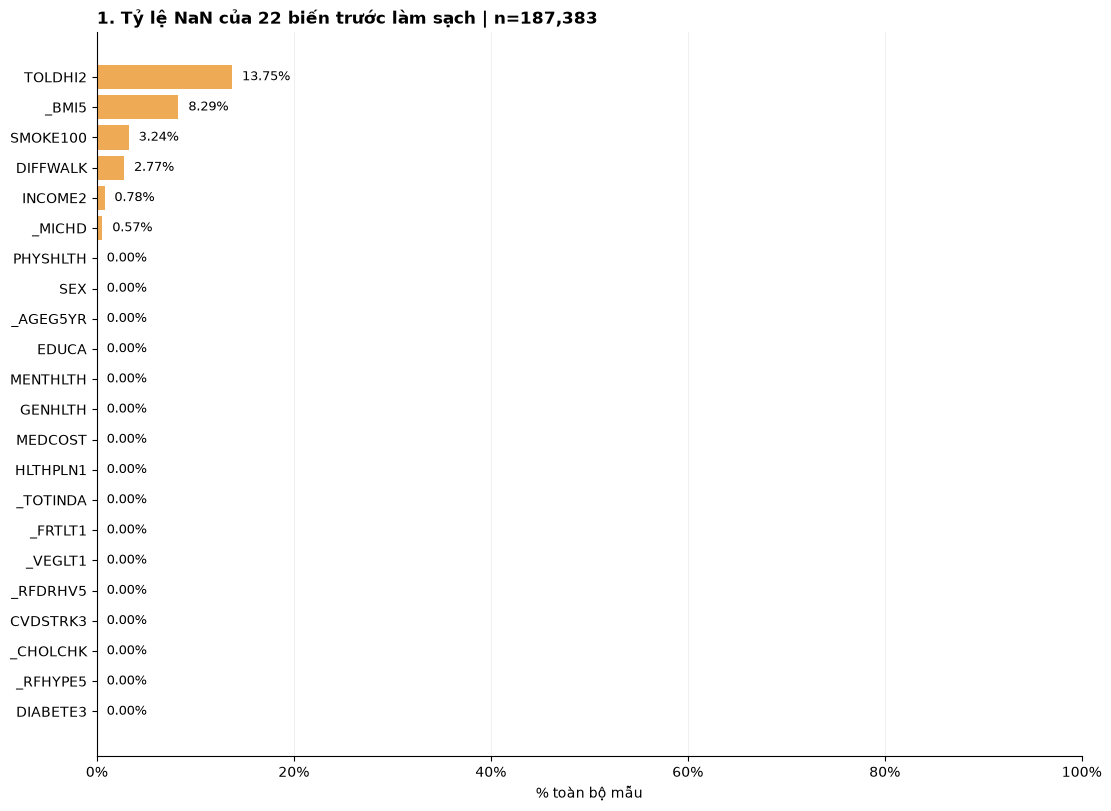

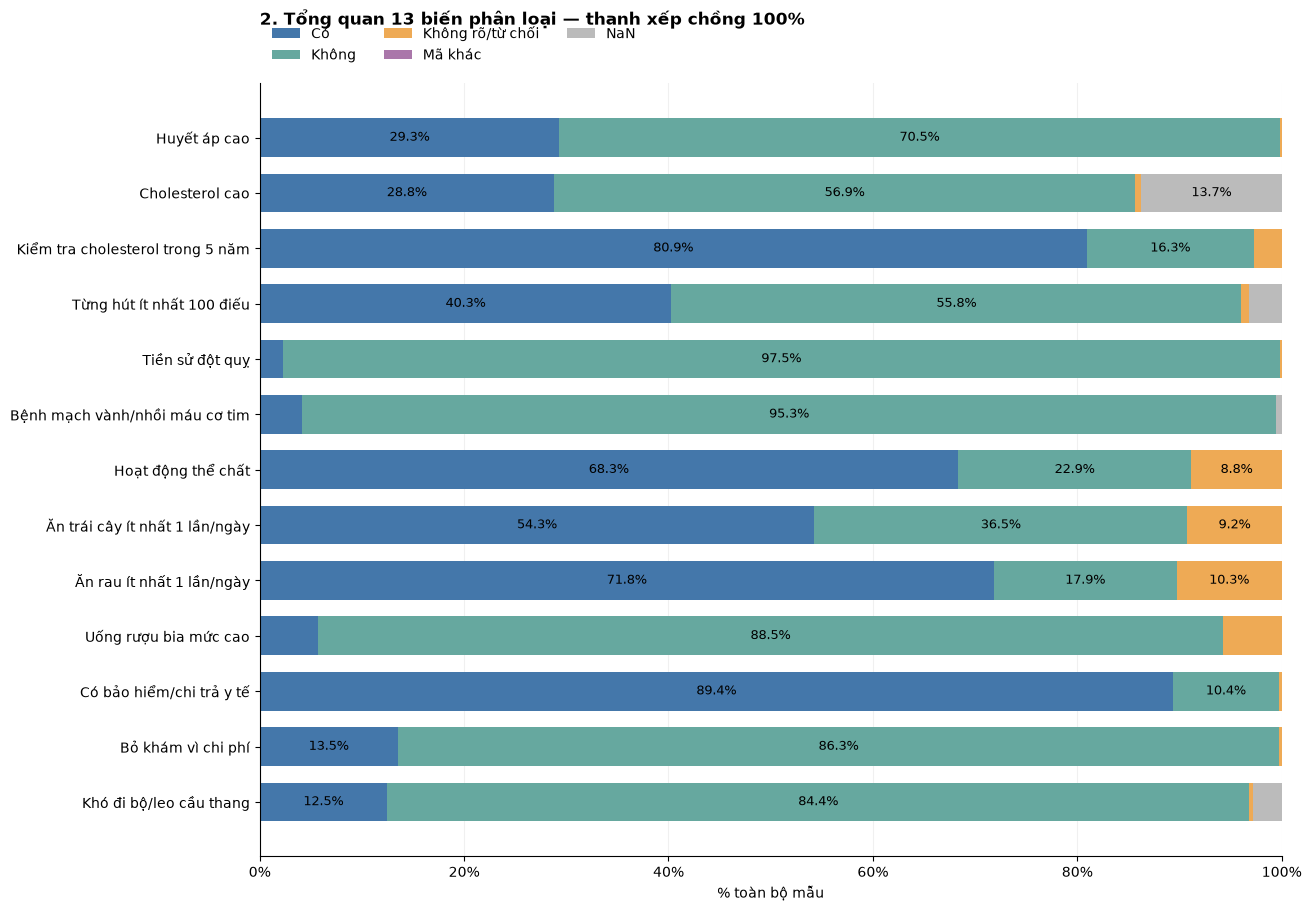

**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.

,Có,Không,Không rõ/từ chối,Mã khác,NaN
Huyết áp cao,29.32,70.48,0.20,0.0,0.00
Cholesterol cao,28.78,56.89,0.58,0.0,13.75
Kiểm tra cholesterol trong 5 năm,80.93,16.35,2.72,0.0,0.00
Từng hút ít nhất 100 điếu,40.28,55.78,0.69,0.0,3.24
Tiền sử đột quỵ,2.28,97.50,0.21,0.0,0.00
Bệnh mạch vành/nhồi máu cơ tim,4.16,95.27,0.00,0.0,0.57
Hoạt động thể chất,68.31,22.86,8.83,0.0,0.00
Ăn trái cây ít nhất 1 lần/ngày,54.25,36.52,9.22,0.0,0.00
Ăn rau ít nhất 1 lần/ngày,71.83,17.90,10.27,0.0,0.00
Uống rượu bia mức cao,5.71,88.53,5.76,0.0,0.00


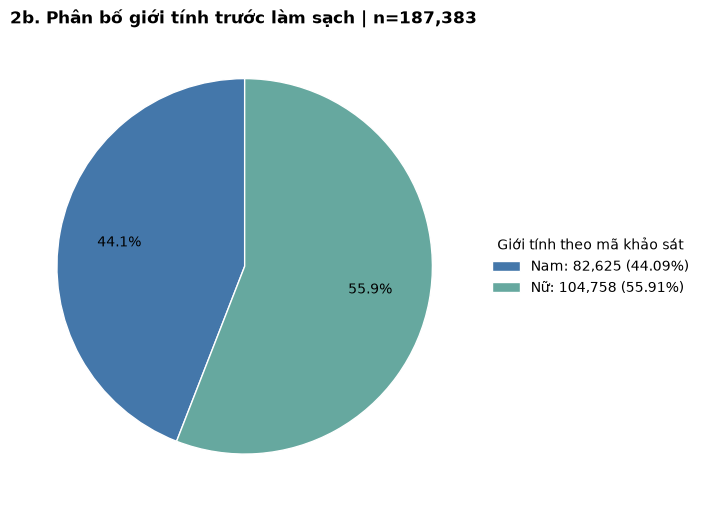

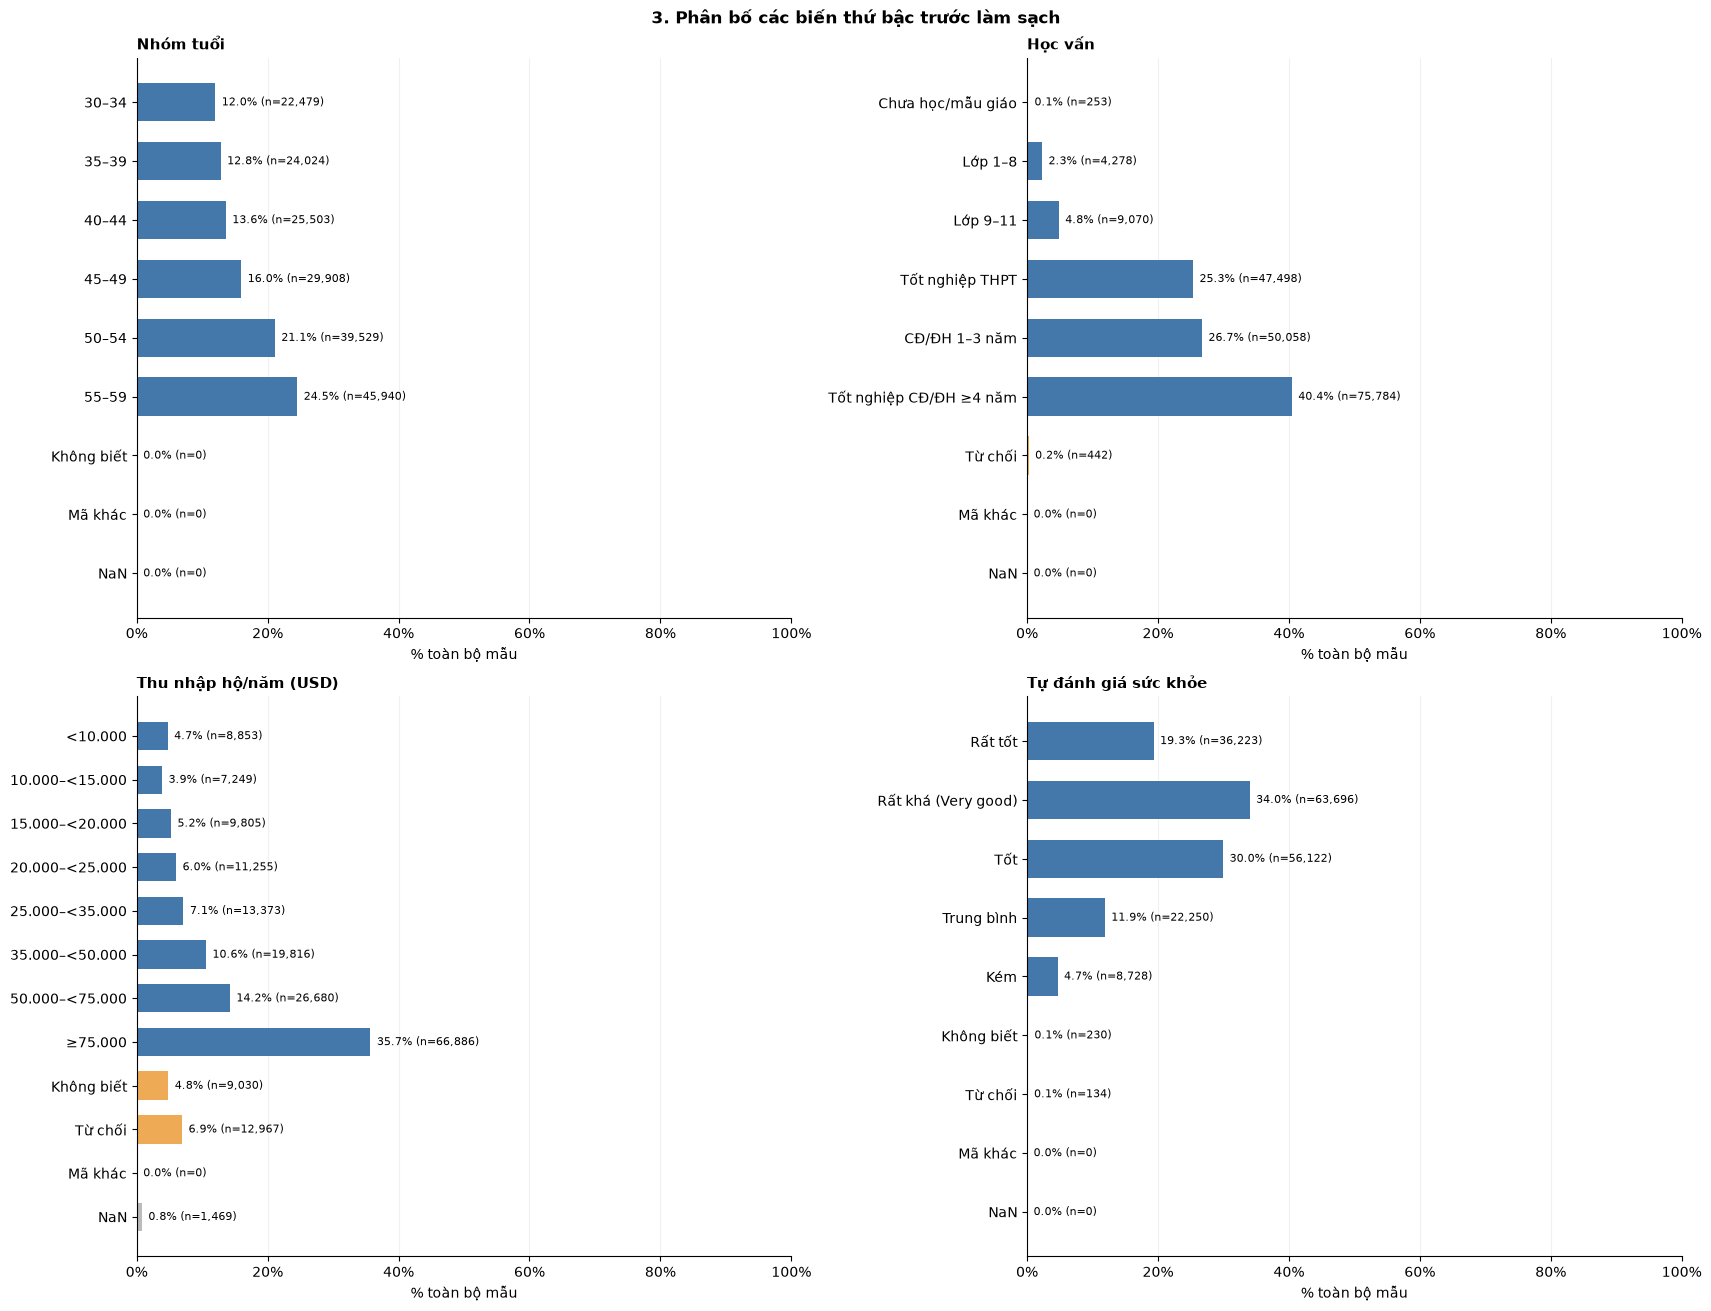

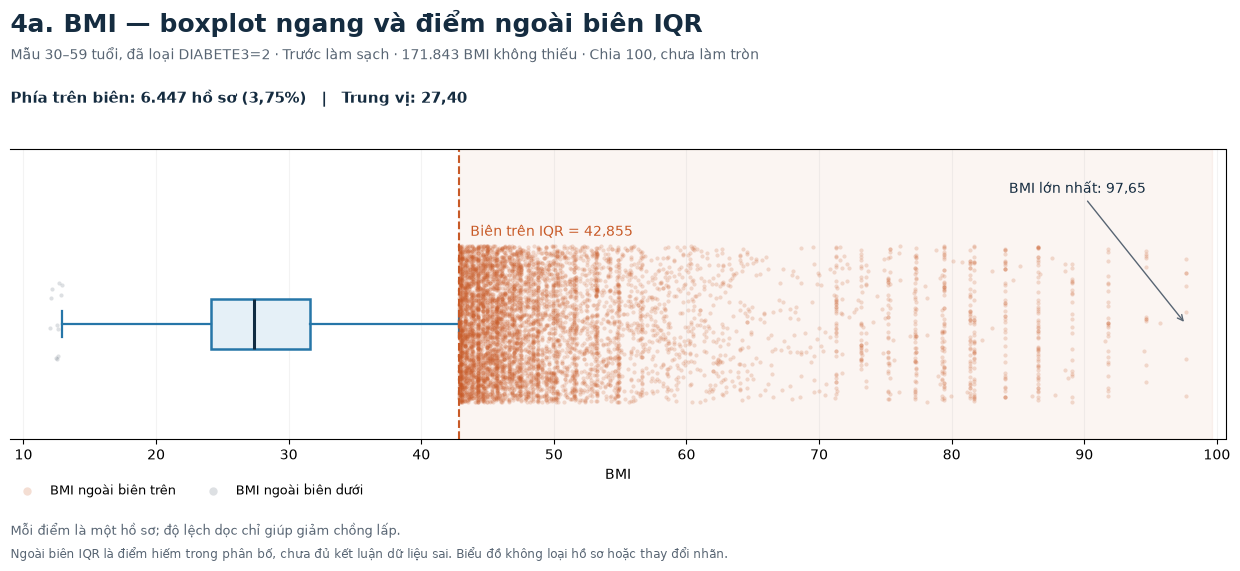

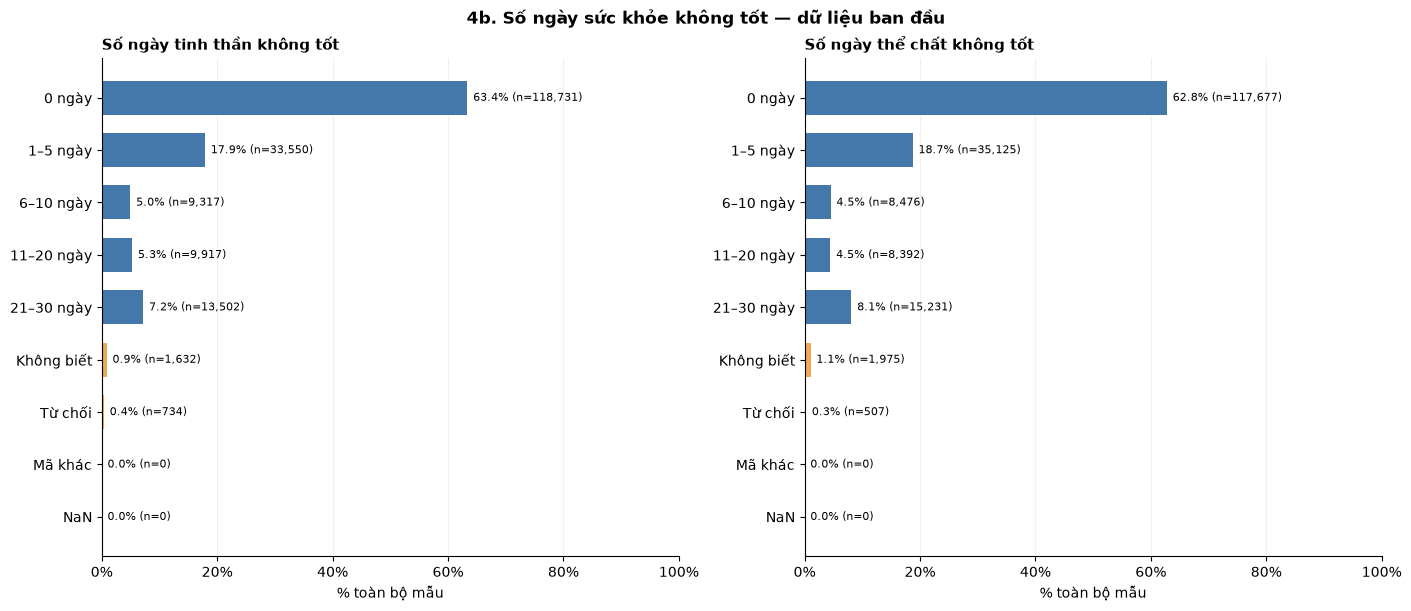

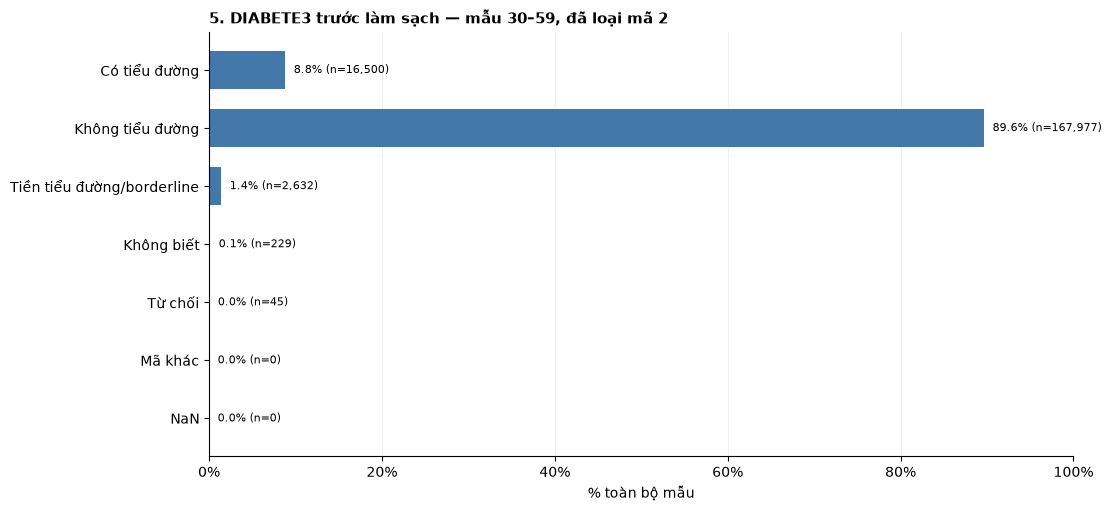

**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. NaN và mã không biết/từ chối là hai loại khác nhau. BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. **Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**

In [6]:
# TỔNG QUAN DỮ LIỆU BAN ĐẦU — MỤC 2.2
# Chỉ đổi nhãn/đơn vị để hiển thị; không sửa df_selected_raw.
def plot_initial_bmi_boxplot(raw):
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mticker

    bmi = (raw['_BMI5'] / 100).dropna()
    if bmi.empty:
        raise ValueError('BMI không có giá trị quan sát trong mẫu nghiên cứu.')
    q1, q3 = bmi.quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    right = bmi[bmi > hi].to_numpy()
    left = bmi[bmi < lo].to_numpy()
    fmt = lambda n: f'{int(n):,}'.replace(',', '.')
    decimal = lambda v, d=2: f'{v:.{d}f}'.replace('.', ',')
    blue, orange, gray, pale = '#2676A8', '#C85A27', '#586573', '#E5F0F7'
    subtitle = (f'Mẫu 30–59 tuổi, đã loại DIABETE3=2 · Trước làm sạch · '
                f'{fmt(len(bmi))} BMI không thiếu · Chia 100, chưa làm tròn')
    footer = ('Ngoài biên IQR là điểm hiếm trong phân bố, chưa đủ kết luận dữ liệu sai. '
              'Biểu đồ không loại hồ sơ hoặc thay đổi nhãn.')
    fig,ax=plt.subplots(figsize=(13.5,5.8))
    fig.subplots_adjust(left=.07,right=.97,bottom=.23,top=.73)
    fig.suptitle('4a. BMI — boxplot ngang và điểm ngoài biên IQR',x=.07,ha='left',y=.97,
        fontsize=18,fontweight='bold',color='#152C40')
    fig.text(.07,.885,subtitle,fontsize=10,color=gray)
    ax.axvspan(hi,bmi.max()+2,color=orange,alpha=.06,zorder=0)
    ax.boxplot(bmi.to_numpy(),orientation='horizontal',positions=[0],widths=.22,
        patch_artist=True,showfliers=False,
        boxprops={'facecolor':pale,'edgecolor':blue,'linewidth':1.8},
        whiskerprops={'color':blue,'linewidth':1.6},capprops={'color':blue,'linewidth':1.6},
        medianprops={'color':'#102C42','linewidth':2.2},manage_ticks=False)
    rng=np.random.default_rng(42)
    for values,color,label in [(right,orange,'BMI ngoài biên trên'),(left,gray,'BMI ngoài biên dưới')]:
        ax.scatter(values,rng.uniform(-.34,.34,len(values)),s=9,alpha=.20,color=color,
            linewidths=0,rasterized=True,label=label,zorder=3)
    ax.axvline(hi,color=orange,linestyle='--',linewidth=1.5)
    ax.annotate(f'Biên trên IQR = {decimal(hi,3)}',xy=(hi,.40),xytext=(8,0),
        textcoords='offset points',color=orange,fontsize=10,va='center')
    ax.annotate(f'BMI lớn nhất: {decimal(bmi.max())}',xy=(bmi.max(),0),
        xytext=(bmi.max()-3,.57),ha='right',fontsize=10,color='#152C40',
        arrowprops={'arrowstyle':'->','color':gray,'linewidth':1})
    ax.set(xlabel='BMI',yticks=[],ylim=(-.5,.76),xlim=(max(0,bmi.min()-3),bmi.max()+3))
    ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
    ax.grid(axis='x',alpha=.15);ax.spines['left'].set_visible(False)
    handles,labels=ax.get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower left',bbox_to_anchor=(.065,.11),ncol=2,
        frameon=False,fontsize=9,markerscale=2)
    fig.text(.07,.81,
        f'Phía trên biên: {fmt(len(right))} hồ sơ ({decimal(len(right)/len(bmi)*100)}%)'
        f'   |   Trung vị: {decimal(bmi.median())}',fontsize=11,fontweight='bold',color='#152C40')
    fig.text(.07,.065,'Mỗi điểm là một hồ sơ; độ lệch dọc chỉ giúp giảm chồng lấp.',fontsize=9,color=gray)
    fig.text(.07,.025,footer,fontsize=8.6,color=gray)
    plt.show()
    plt.close(fig)


def plot_initial_overview(raw):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    n = len(raw)
    if n == 0:
        raise ValueError('Dữ liệu ban đầu chưa có dòng nào.')
    blue, teal, orange, gray = '#4477AA', '#66A89F', '#EEAA55', '#BBBBBB'
    display(Markdown(
        '### Biểu đồ tổng quan dữ liệu ban đầu (mục 2.2)\n'
        f'**Mẫu 30–59, đã loại DIABETE3=2: {n:,} dòng × {raw.shape[1]} cột.** '
        'Các tỷ lệ dùng toàn bộ số dòng làm mẫu số, kể cả NaN. '
        'Chia nhóm biến để tránh chênh lệch thang đo; giữ nguyên tỷ lệ thực tế, '
        'không cân bằng mẫu. Đây là tỷ lệ trong file, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        axis = 'x' if horizontal else 'y'
        ax.grid(axis=axis, alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def distribution(series, mapping):
        labels = series.map(mapping)
        labels = labels.where(series.notna(), 'NaN')
        labels = labels.fillna('Mã khác')
        order = list(dict.fromkeys(mapping.values())) + ['Mã khác', 'NaN']
        counts = labels.value_counts().reindex(order, fill_value=0)
        return counts

    def barh(ax, counts, title):
        pct = counts / n * 100
        colors = [gray if k == 'NaN' else orange if k in
                  ['Không biết', 'Từ chối', 'Mã khác'] else blue for k in counts.index]
        bars = ax.barh(counts.index, pct, color=colors, height=.65)
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_title(title, loc='left', fontsize=11, fontweight='bold')
        ax.set_xlabel('% toàn bộ mẫu')
        for b, p, count in zip(bars, pct, counts):
            ax.text(min(p + 1, 97), b.get_y()+b.get_height()/2,
                    f'{p:.1f}% (n={count:,})', va='center', fontsize=8,
                    ha='right' if p > 94 else 'left')
        style(ax, True)

    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
        # 1. NaN của toàn bộ 22 cột.
        missing = (raw.isna().mean()*100).sort_values(ascending=True)
        fig, ax = plt.subplots(figsize=(11, 8), layout='constrained')
        bars = ax.barh(missing.index, missing.values, color=orange)
        ax.set_xlim(0, 100)
        ax.set_title(f'1. Tỷ lệ NaN của 22 biến trước làm sạch | n={n:,}',
                     loc='left', fontweight='bold')
        ax.set_xlabel('% toàn bộ mẫu')
        for b, p in zip(bars, missing.values):
            ax.text(min(p+1, 98), b.get_y()+b.get_height()/2,
                    f'{p:.2f}%', va='center', fontsize=9)
        style(ax, True)
        plt.show()

        # 2. Các biến phân loại. Mã nguồn được đọc theo từng biến.
        specs = [
            ('_RFHYPE5', 'Huyết áp cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('TOLDHI2', 'Cholesterol cao', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_CHOLCHK', 'Kiểm tra cholesterol trong 5 năm', {1:'Có', 2:'Không', 3:'Không', 9:'Không rõ/từ chối'}),
            ('SMOKE100', 'Từng hút ít nhất 100 điếu', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('CVDSTRK3', 'Tiền sử đột quỵ', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('_MICHD', 'Bệnh mạch vành/nhồi máu cơ tim', {1:'Có', 2:'Không'}),
            ('_TOTINDA', 'Hoạt động thể chất', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_FRTLT1', 'Ăn trái cây ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_VEGLT1', 'Ăn rau ít nhất 1 lần/ngày', {1:'Có', 2:'Không', 9:'Không rõ/từ chối'}),
            ('_RFDRHV5', 'Uống rượu bia mức cao', {1:'Không', 2:'Có', 9:'Không rõ/từ chối'}),
            ('HLTHPLN1', 'Có bảo hiểm/chi trả y tế', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('MEDCOST', 'Bỏ khám vì chi phí', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'}),
            ('DIFFWALK', 'Khó đi bộ/leo cầu thang', {1:'Có', 2:'Không', 7:'Không rõ/từ chối', 9:'Không rõ/từ chối'})]
        categories = ['Có', 'Không', 'Không rõ/từ chối', 'Mã khác', 'NaN']
        rows = []
        for col, title, mapping in specs:
            s = raw[col].map(mapping)
            s = s.where(raw[col].notna(), 'NaN').fillna('Mã khác')
            rows.append(s.value_counts().reindex(categories, fill_value=0)/n*100)
        table = pd.DataFrame(rows, index=[title for _, title, _ in specs])
        fig, ax = plt.subplots(figsize=(13, 9), layout='constrained')
        left = np.zeros(len(table))
        for category, color in zip(categories, [blue, teal, orange, '#AA77AA', gray]):
            widths = table[category].to_numpy()
            ax.barh(table.index, widths, left=left, color=color, label=category, height=.7)
            for y, (start, width) in enumerate(zip(left, widths)):
                if width >= 6:
                    ax.text(start+width/2, y, f'{width:.1f}%', ha='center', va='center', fontsize=9)
            left += widths
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel('% toàn bộ mẫu')
        ax.set_title('2. Tổng quan 13 biến phân loại — thanh xếp chồng 100%',
                     loc='left', fontweight='bold', pad=42)
        ax.legend(ncol=3, loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False)
        style(ax, True)
        plt.show()
        display(Markdown('**Tỷ lệ chi tiết (%):** bảng dưới giữ cả nhóm nhỏ không đủ chỗ ghi trên thanh. '
                         'Giới tính được trình bày bằng biểu đồ tròn riêng bên dưới.'))
        display(table.round(2))

        # 2b. Giới tính tách riêng thành biểu đồ tròn, giữ cả NaN/mã khác.
        sex_counts = distribution(raw['SEX'], {1:'Nam', 2:'Nữ', 9:'Không rõ/từ chối'})
        sex_counts = sex_counts[sex_counts > 0]
        sex_palette = {'Nam':blue, 'Nữ':teal, 'Không rõ/từ chối':orange,
                       'Mã khác':'#AA77AA', 'NaN':gray}
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        wedges, _, _ = ax.pie(sex_counts.values,
            colors=[sex_palette[k] for k in sex_counts.index], startangle=90,
            autopct=lambda p: f'{p:.1f}%' if p >= 1 else '',
            pctdistance=.68, wedgeprops={'edgecolor':'white', 'linewidth':1})
        ax.legend(wedges, [f'{k}: {v:,} ({v/n*100:.2f}%)'
                          for k,v in sex_counts.items()],
                  title='Giới tính theo mã khảo sát', loc='center left',
                  bbox_to_anchor=(1, .5), frameon=False)
        ax.set_title(f'2b. Phân bố giới tính trước làm sạch | n={n:,}',
                     loc='left', fontweight='bold')
        ax.set_aspect('equal')
        plt.show()

        # 3. Biến thứ bậc, giữ đúng thứ tự và tách mã phản hồi.
        age = ['30–34','35–39','40–44','45–49','50–54','55–59']
        ordinal = [
            ('_AGEG5YR', 'Nhóm tuổi', {**dict(enumerate(age, 3)), 14:'Không biết'}),
            ('EDUCA', 'Học vấn', {1:'Chưa học/mẫu giáo', 2:'Lớp 1–8', 3:'Lớp 9–11',
                4:'Tốt nghiệp THPT', 5:'CĐ/ĐH 1–3 năm', 6:'Tốt nghiệp CĐ/ĐH ≥4 năm', 9:'Từ chối'}),
            ('INCOME2', 'Thu nhập hộ/năm (USD)', {1:'<10.000', 2:'10.000–<15.000',
                3:'15.000–<20.000', 4:'20.000–<25.000', 5:'25.000–<35.000',
                6:'35.000–<50.000', 7:'50.000–<75.000', 8:'≥75.000', 77:'Không biết', 99:'Từ chối'}),
            ('GENHLTH', 'Tự đánh giá sức khỏe', {1:'Rất tốt', 2:'Rất khá (Very good)',
                3:'Tốt', 4:'Trung bình', 5:'Kém', 7:'Không biết', 9:'Từ chối'})]
        fig, axes = plt.subplots(2, 2, figsize=(17, 13), layout='constrained')
        fig.suptitle('3. Phân bố các biến thứ bậc trước làm sạch', fontweight='bold')
        for ax, (col, title, mapping) in zip(axes.flat, ordinal):
            barh(ax, distribution(raw[col], mapping), title)
        plt.show()

        # 4a. Boxplot BMI: giữ toàn bộ miền và vẽ các điểm ngoài biên.
        plot_initial_bmi_boxplot(raw)

        # 4b. Hai biểu đồ số ngày giữ cách đếm và giải mã hiện tại.
        fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout='constrained')
        days_mapping = {0:'0 ngày', 88:'0 ngày',
                        **{i:'1–5 ngày' for i in range(1, 6)},
                        **{i:'6–10 ngày' for i in range(6, 11)},
                        **{i:'11–20 ngày' for i in range(11, 21)},
                        **{i:'21–30 ngày' for i in range(21, 31)},
                        77:'Không biết', 99:'Từ chối'}
        for ax, col, title in zip(axes, ['MENTHLTH', 'PHYSHLTH'],
                                  ['Số ngày tinh thần không tốt', 'Số ngày thể chất không tốt']):
            barh(ax, distribution(raw[col], days_mapping), title)
        fig.suptitle('4b. Số ngày sức khỏe không tốt — dữ liệu ban đầu', fontweight='bold')
        plt.show()

        # 5. Nhãn gốc: chưa gộp Diabetes_binary.
        target_map = {1:'Có tiểu đường', 3:'Không tiểu đường',
                      4:'Tiền tiểu đường/borderline', 7:'Không biết', 9:'Từ chối'}
        fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
        barh(ax, distribution(raw['DIABETE3'], target_map),
             '5. DIABETE3 trước làm sạch — mẫu 30–59, đã loại mã 2')
        plt.show()
        display(Markdown('**Cách đọc:** thanh 100% giúp so sánh cơ cấu các biến; '
            'các nhóm ít mẫu vẫn được giữ và ghi trong bảng tỷ lệ. '
            'NaN và mã không biết/từ chối là hai loại khác nhau. '
            'BMI chia 100 và giữ phần thập phân; boxplot hiển thị điểm ngoài biên IQR. 88 ở số ngày được hiển thị là 0 ngày. '
            '**Ô vẽ không thay đổi mẫu đã chọn, không sửa dữ liệu nguồn và không cân bằng lại các lớp.**'))

plot_initial_overview(df_selected_raw)


### NHẬN XÉT VÀ QUAN SÁT (Mục 2.2)

- Nguồn toàn bộ được kiểm tra riêng; nhật ký chọn phạm vi ghi số hồ sơ còn lại sau chọn tuổi 30–59 và loại tiểu đường chỉ khi mang thai.
- Các biểu đồ ban đầu dùng `df_selected_raw`: mẫu đã chọn, trước xử lý thiếu và mã khảo sát. Tỷ lệ mô tả mẫu này, chưa có trọng số khảo sát.
- Age là sáu nhóm tuổi mã 3–8. Thu nhập, học vấn và sức khỏe chung vẫn là mã thứ bậc.
- Phân biệt NaN với mã không biết/từ chối; không gộp các trường hợp đó thành câu trả lời “không”. BMI chỉ đổi đơn vị phục vụ hiển thị ở bước này.
- Nhãn gốc còn mã 1, 3, 4, có thể có 7/9/NaN; mã 2 đã loại ở bước chọn mẫu. Sau làm sạch, gộp 1 và 4 thành lớp 1; mã 3 thành lớp 0.
- Không diễn giải phân bố như nguy cơ phát bệnh tương lai hoặc kết luận nhân quả.



# PART 3: DATA CLEANING & PREPROCESSING [4.0 POINTS]

### Mandatory Tasks:
1. **Duplicate:** Phát hiện và loại các dòng trùng lặp.
2. **Missing:** Tính tỷ lệ thiếu, xác định cách xử lý và giải thích lựa chọn.
3. **Kiểu dữ liệu và định dạng:** Chuyển sang kiểu phù hợp; chuẩn hóa văn bản, khoảng trắng và chữ hoa/thường khi có áp dụng.
4. **Outlier:** Dùng boxplot/IQR để phát hiện và xử lý giá trị cực đoan bằng phương pháp phù hợp.


#### STUDENT TASK 3.1: CHECK & HANDLE DUPLICATE DATA

Kiểm tra duplicate trên toàn bộ 330 cột nguồn, 22 cột toàn nguồn và 22 cột của mẫu 30–59 đã loại DIABETE3=2. Sau chuyển mã, làm tròn BMI và gộp nhãn, kiểm tra lại trên đầu ra. Bản chính giữ hồ sơ trùng đặc điểm; bản xóa duplicate ở mục 3.4 phục vụ đối chiếu.

Nhóm thực hiện cả phát hiện và loại duplicate trong ongoing 1. Bản chính giữ các hồ sơ trùng đặc điểm vì chưa đủ căn cứ xác định chúng thuộc cùng một người; bản đối chiếu sử dụng `drop_duplicates()` để giữ một dòng cho mỗi tổ hợp giá trị trên 22 cột. Hai bản được xuất riêng để phục vụ nghiên cứu tiếp theo.


In [7]:
print('Duplicate toàn bộ cột nguồn:', int(df_brfss_raw.duplicated().sum()))
print('Duplicate trên 22 cột toàn nguồn:', int(df_selected_all.duplicated().sum()))
print('Duplicate trên 22 cột mẫu nghiên cứu trước clean:', int(df_selected_raw.duplicated().sum()))


Duplicate toàn bộ cột nguồn: 0
Duplicate trên 22 cột toàn nguồn: 7098
Duplicate trên 22 cột mẫu nghiên cứu trước clean: 4385


**NHẬN XÉT (Mục 3.1):**

**Kết quả mẫu mới:** Trước clean có 4.385 dòng trùng trên 22 cột. Sau clean, bản chính có 116.662 dòng, trong đó 13.836 dòng trùng ngoài lần đầu; bản đối chiếu còn 102.826 dòng. Trong bản chính, lớp 0 có 103.921 và lớp 1 có 12.741 dòng.

Các số duplicate trước làm sạch được in ở trên. Bản chính giữ duplicate vì hai người có thể trùng đặc điểm trong 22 cột; việc trùng chưa chứng minh cùng một người. Mục 3.4 trình bày số dòng và tỷ lệ nhãn của hai bản sau làm sạch, tính lại cho mẫu mới. Chuyển mã, làm tròn BMI và gộp nhãn có thể tạo thêm các tổ hợp trùng.


#### STUDENT TASK 3.2: CHECK & HANDLE MISSING VALUES

Nhóm thống kê số ô NaN và tỷ lệ NaN của từng cột trong 22 biến được chọn. Sau đó, nhóm xóa dòng chứa NaN, xử lý mã không biết/từ chối trả lời và ghi lại số dòng bị loại ở từng bước. Mã 88 trong `MENTHLTH` và `PHYSHLTH` được đổi thành 0 ngày.


**Ghi chú về lý do loại dòng và quy trình kế thừa:** Nhóm kế thừa hoàn toàn cách xử lý NaN bằng loại dòng (complete-case deletion) của notebook tham khảo Alex Teboul trên bộ 22 biến được chọn. Các dòng thiếu nhãn phân loại tiểu đường ở cột nguồn `DIABETE3` được loại vì không có nhãn để huấn luyện và đánh giá bài toán phân loại có giám sát; nhóm không tự suy đoán hoặc điền nhãn cho các dòng này. Trong code hiện tại, `dropna()` áp dụng trên cả 22 cột nên đồng thời loại các dòng thiếu biến đầu vào, không chỉ các dòng thiếu nhãn.

**Phạm vi đếm:** Chỉ `df_selected_raw` (30–59, không có DIABETE3=2). Số bị loại do chọn phạm vi nằm ở nhật ký riêng, không tính thành mất mẫu do missing. Giữ nguyên `dropna()` trên cả 22 cột và các quy tắc mã phản hồi của bản trước.


In [8]:
# Kiểm tra NaN sau khi loại dòng thiếu ở 4 biến trên bản sao.
# Không thay đổi dữ liệu nguồn hoặc cách làm sạch chính.
import pandas as pd
from IPython.display import display

nan_drop_columns = ['TOLDHI2', '_BMI5', 'SMOKE100', '_MICHD']
df_drop_nan_4vars = df_selected_raw.dropna(subset=nan_drop_columns).copy()
print('Các cột dùng để lọc NaN:', ', '.join(nan_drop_columns))
print(f'Trước lọc: {len(df_selected_raw):,} dòng; sau lọc: {len(df_drop_nan_4vars):,} dòng.')
print(f'Số dòng bị loại: {len(df_selected_raw)-len(df_drop_nan_4vars):,}.')

remaining_nan_columns = [c for c in df_drop_nan_4vars.columns if c not in nan_drop_columns]
remaining_nan_summary = pd.DataFrame({
    'Cột còn lại': remaining_nan_columns,
    'Số dòng NaN': [int(df_drop_nan_4vars[c].isna().sum()) for c in remaining_nan_columns],
    'Tỷ lệ NaN (%)': [df_drop_nan_4vars[c].isna().mean()*100 for c in remaining_nan_columns],
    'Số dòng không NaN': [int(df_drop_nan_4vars[c].notna().sum()) for c in remaining_nan_columns]
})
print('BẢNG TỔNG HỢP NaN CỦA 18 CỘT CÒN LẠI SAU DROP NaN Ở 4 BIẾN')
display(remaining_nan_summary)
remaining_any_nan = df_drop_nan_4vars[remaining_nan_columns].isna().any(axis=1)
print(f'Tổng số ô NaN còn lại: {int(remaining_nan_summary["Số dòng NaN"].sum()):,}')
print(f'Số dòng có ít nhất một NaN ở các cột còn lại: {int(remaining_any_nan.sum()):,}')
print('Chỉ đếm NaN thực tế; các mã không biết/từ chối chưa được đổi thành NaN ở bảng này.')
print('Giữ nguyên dropna trên 22 cột và quy tắc xử lý mã khảo sát ở bước làm sạch chính.')


Các cột dùng để lọc NaN: TOLDHI2, _BMI5, SMOKE100, _MICHD
Trước lọc: 187,383 dòng; sau lọc: 145,580 dòng.
Số dòng bị loại: 41,803.
BẢNG TỔNG HỢP NaN CỦA 18 CỘT CÒN LẠI SAU DROP NaN Ở 4 BIẾN


,Cột còn lại,Số dòng NaN,Tỷ lệ NaN (%),Số dòng không NaN
0,DIABETE3,0,0.000000,145580
1,_RFHYPE5,0,0.000000,145580
2,_CHOLCHK,0,0.000000,145580
3,CVDSTRK3,0,0.000000,145580
4,_TOTINDA,0,0.000000,145580
5,_FRTLT1,0,0.000000,145580
6,_VEGLT1,0,0.000000,145580
7,_RFDRHV5,0,0.000000,145580
8,HLTHPLN1,0,0.000000,145580
9,MEDCOST,0,0.000000,145580


Tổng số ô NaN còn lại: 2
Số dòng có ít nhất một NaN ở các cột còn lại: 2
Chỉ đếm NaN thực tế; các mã không biết/từ chối chưa được đổi thành NaN ở bảng này.
Giữ nguyên dropna trên 22 cột và quy tắc xử lý mã khảo sát ở bước làm sạch chính.


In [9]:
missing_summary = pd.DataFrame({
    "Số ô NaN": df_selected_raw.isna().sum(),
    "Tỷ lệ NaN (%)": df_selected_raw.isna().mean() * 100
}).sort_values("Số ô NaN", ascending=False)

display(missing_summary)
print("Tổng ô NaN:", int(df_selected_raw.isna().sum().sum()))
print("Số dòng chứa NaN:", int(df_selected_raw.isna().any(axis=1).sum()))

brfss_df_selected = df_selected_raw.copy(deep=True)
audit_rows = []
before = len(brfss_df_selected)
# Xóa dòng chứa NaN trên đủ 22 cột trong mẫu nghiên cứu.
brfss_df_selected = brfss_df_selected.dropna()
brfss_df_selected.shape
audit_rows.append(['NaN', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
# DIABETE3
# Mã 2 đã bị loại khi chọn mẫu; tuyệt đối không gộp sang lớp 0 hoặc 1.
assert not brfss_df_selected['DIABETE3'].eq(2).any()
# Nhãn: DIABETE3=3 -> 0; DIABETE3=1,4 -> 1.
# Remove all 7 (dont knows)
# Remove all 9 (refused)
brfss_df_selected['DIABETE3'] = brfss_df_selected['DIABETE3'].replace({3:0, 1:1, 4:1})
brfss_df_selected = brfss_df_selected[brfss_df_selected.DIABETE3 != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.DIABETE3 != 9]
brfss_df_selected.DIABETE3.unique()
audit_rows.append(['DIABETE3', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#1 _RFHYPE5
#Change 1 to 0 so it represetnts No high blood pressure and 2 to 1 so it represents high blood pressure
brfss_df_selected['_RFHYPE5'] = brfss_df_selected['_RFHYPE5'].replace({1:0, 2:1})
brfss_df_selected = brfss_df_selected[brfss_df_selected._RFHYPE5 != 9]
brfss_df_selected._RFHYPE5.unique()
audit_rows.append(['_RFHYPE5', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#2 TOLDHI2
# Change 2 to 0 because it is No
# Remove all 7 (dont knows)
# Remove all 9 (refused)
brfss_df_selected['TOLDHI2'] = brfss_df_selected['TOLDHI2'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.TOLDHI2 != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.TOLDHI2 != 9]
brfss_df_selected.TOLDHI2.unique()
audit_rows.append(['TOLDHI2', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#3 _CHOLCHK
# Change 3 to 0 and 2 to 0 for Not checked cholesterol in past 5 years
# Remove 9
brfss_df_selected['_CHOLCHK'] = brfss_df_selected['_CHOLCHK'].replace({3:0,2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected._CHOLCHK != 9]
brfss_df_selected._CHOLCHK.unique()
audit_rows.append(['_CHOLCHK', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#4 _BMI5 (no changes, just note that these are BMI * 100. So for example a BMI of 4018 is really 40.18)
brfss_df_selected['_BMI5'] = brfss_df_selected['_BMI5'].div(100).round(0)
brfss_df_selected._BMI5.unique()
audit_rows.append(['_BMI5', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#5 SMOKE100
# Change 2 to 0 because it is No
# Remove all 7 (dont knows)
# Remove all 9 (refused)
brfss_df_selected['SMOKE100'] = brfss_df_selected['SMOKE100'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.SMOKE100 != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.SMOKE100 != 9]
brfss_df_selected.SMOKE100.unique()
audit_rows.append(['SMOKE100', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#6 CVDSTRK3
# Change 2 to 0 because it is No
# Remove all 7 (dont knows)
# Remove all 9 (refused)
brfss_df_selected['CVDSTRK3'] = brfss_df_selected['CVDSTRK3'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.CVDSTRK3 != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.CVDSTRK3 != 9]
brfss_df_selected.CVDSTRK3.unique()
audit_rows.append(['CVDSTRK3', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#7 _MICHD
#Change 2 to 0 because this means did not have MI or CHD
brfss_df_selected['_MICHD'] = brfss_df_selected['_MICHD'].replace({2: 0})
brfss_df_selected._MICHD.unique()
audit_rows.append(['_MICHD', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#8 _TOTINDA
# 1 for physical activity
# change 2 to 0 for no physical activity
# Remove all 9 (don't know/refused)
brfss_df_selected['_TOTINDA'] = brfss_df_selected['_TOTINDA'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected._TOTINDA != 9]
brfss_df_selected._TOTINDA.unique()
audit_rows.append(['_TOTINDA', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#9 _FRTLT1
# Fruits: 0 = dưới 1 lần/ngày; 1 = từ 1 lần/ngày trở lên.
# Tần suất bao gồm trái cây và nước ép trái cây 100%.
# remove all dont knows and missing 9
brfss_df_selected['_FRTLT1'] = brfss_df_selected['_FRTLT1'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected._FRTLT1 != 9]
brfss_df_selected._FRTLT1.unique()
audit_rows.append(['_FRTLT1', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#10 _VEGLT1
# Veggies: 0 = dưới 1 lần/ngày; 1 = từ 1 lần/ngày trở lên.
# Giá trị 0 không có nghĩa là hoàn toàn không tiêu thụ.
# remove all dont knows and missing 9
brfss_df_selected['_VEGLT1'] = brfss_df_selected['_VEGLT1'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected._VEGLT1 != 9]
brfss_df_selected._VEGLT1.unique()
audit_rows.append(['_VEGLT1', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#11 _RFDRHV5
# Change 1 to 0 (1 was no for heavy drinking). change all 2 to 1 (2 was yes for heavy drinking)
# remove all dont knows and missing 9
brfss_df_selected['_RFDRHV5'] = brfss_df_selected['_RFDRHV5'].replace({1:0, 2:1})
brfss_df_selected = brfss_df_selected[brfss_df_selected._RFDRHV5 != 9]
brfss_df_selected._RFDRHV5.unique()
audit_rows.append(['_RFDRHV5', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#12 HLTHPLN1
# 1 is yes, change 2 to 0 because it is No health care access
# remove 7 and 9 for don't know or refused
brfss_df_selected['HLTHPLN1'] = brfss_df_selected['HLTHPLN1'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.HLTHPLN1 != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.HLTHPLN1 != 9]
brfss_df_selected.HLTHPLN1.unique()
audit_rows.append(['HLTHPLN1', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#13 MEDCOST
# Change 2 to 0 for no, 1 is already yes
# remove 7 for don/t know and 9 for refused
brfss_df_selected['MEDCOST'] = brfss_df_selected['MEDCOST'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.MEDCOST != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.MEDCOST != 9]
brfss_df_selected.MEDCOST.unique()
audit_rows.append(['MEDCOST', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#14 GENHLTH
# This is an ordinal variable that I want to keep (1 is Excellent -> 5 is Poor)
# Remove 7 and 9 for don't know and refused
brfss_df_selected = brfss_df_selected[brfss_df_selected.GENHLTH != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.GENHLTH != 9]
brfss_df_selected.GENHLTH.unique()
audit_rows.append(['GENHLTH', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#15 MENTHLTH
# already in days so keep that, scale will be 0-30
# change 88 to 0 because it means none (no bad mental health days)
# remove 77 and 99 for don't know not sure and refused
brfss_df_selected['MENTHLTH'] = brfss_df_selected['MENTHLTH'].replace({88:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.MENTHLTH != 77]
brfss_df_selected = brfss_df_selected[brfss_df_selected.MENTHLTH != 99]
brfss_df_selected.MENTHLTH.unique()
audit_rows.append(['MENTHLTH', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#16 PHYSHLTH
# already in days so keep that, scale will be 0-30
# change 88 to 0 because it means none (no bad mental health days)
# remove 77 and 99 for don't know not sure and refused
brfss_df_selected['PHYSHLTH'] = brfss_df_selected['PHYSHLTH'].replace({88:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.PHYSHLTH != 77]
brfss_df_selected = brfss_df_selected[brfss_df_selected.PHYSHLTH != 99]
brfss_df_selected.PHYSHLTH.unique()
audit_rows.append(['PHYSHLTH', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#17 DIFFWALK
# change 2 to 0 for no. 1 is already yes
# remove 7 and 9 for don't know not sure and refused
brfss_df_selected['DIFFWALK'] = brfss_df_selected['DIFFWALK'].replace({2:0})
brfss_df_selected = brfss_df_selected[brfss_df_selected.DIFFWALK != 7]
brfss_df_selected = brfss_df_selected[brfss_df_selected.DIFFWALK != 9]
brfss_df_selected.DIFFWALK.unique()
audit_rows.append(['DIFFWALK', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#18 SEX
# Giữ mã hóa giới tính của bộ biến tham khảo: 0 nữ, 1 nam.
# change 2 to 0 (female as 0). Male is 1
brfss_df_selected['SEX'] = brfss_df_selected['SEX'].replace({2:0})
brfss_df_selected.SEX.unique()
audit_rows.append(['SEX', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#19 _AGEG5YR
# Giữ mã gốc 3–8 sau khi chọn phạm vi tuổi 30–59.
# remove 14 because it is don't know or missing
brfss_df_selected = brfss_df_selected[brfss_df_selected._AGEG5YR != 14]
brfss_df_selected._AGEG5YR.unique()
audit_rows.append(['_AGEG5YR', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#20 EDUCA
# This is already an ordinal variable with 1 being never attended school or kindergarten only up to 6 being college 4 years or more
# Scale here is 1-6
# Remove 9 for refused:
brfss_df_selected = brfss_df_selected[brfss_df_selected.EDUCA != 9]
brfss_df_selected.EDUCA.unique()
audit_rows.append(['EDUCA', before, before-len(brfss_df_selected), len(brfss_df_selected)])

before = len(brfss_df_selected)
#21 INCOME2
# Variable is already ordinal with 1 being less than $10,000 all the way up to 8 being $75,000 or more
# Remove 77 and 99 for don't know and refused
brfss_df_selected = brfss_df_selected[brfss_df_selected.INCOME2 != 77]
brfss_df_selected = brfss_df_selected[brfss_df_selected.INCOME2 != 99]
brfss_df_selected.INCOME2.unique()
audit_rows.append(['INCOME2', before, before-len(brfss_df_selected), len(brfss_df_selected)])


display(pd.DataFrame(audit_rows, columns=["step","before","removed","after"]))


,Số ô NaN,Tỷ lệ NaN (%)
TOLDHI2,25760,13.747245
_BMI5,15540,8.293175
SMOKE100,6080,3.244691
DIFFWALK,5199,2.774531
INCOME2,1469,0.783956
_MICHD,1065,0.568355
_CHOLCHK,0,0.000000
_RFHYPE5,0,0.000000
DIABETE3,0,0.000000
CVDSTRK3,0,0.000000


Tổng ô NaN: 55113
Số dòng chứa NaN: 41805


,step,before,removed,after
0,NaN,187383,41805,145578
1,DIABETE3,145578,127,145451
2,_RFHYPE5,145451,179,145272
3,TOLDHI2,145272,841,144431
4,_CHOLCHK,144431,1316,143115
5,_BMI5,143115,0,143115
6,SMOKE100,143115,749,142366
7,CVDSTRK3,142366,210,142156
8,_MICHD,142156,0,142156
9,_TOTINDA,142156,6987,135169


**NHẬN XÉT VÀ LÝ DO LỰA CHỌN (Mục 3.2):**

**Kết quả mẫu mới:** 187.383 dòng trước clean có 55.113 ô NaN trên 41.805 dòng. Sau dropna còn 145.578 dòng; các bước mã khảo sát loại tiếp 28.916 dòng, còn 116.662 dòng. Tổng giảm do làm sạch là 37,74% của mẫu đã chọn; không bao gồm hồ sơ ngoài tuổi hoặc DIABETE3=2.

- Bảng missing và nhật ký ở trên tính trực tiếp trên mẫu nghiên cứu, ghi riêng số dòng loại do NaN và từng mã khảo sát. Một dòng nhiều lỗi chỉ được đếm ở bước đầu tiên loại dòng đó.
- Giữ complete-case deletion trên 22 cột theo quy trình hiện tại; không điền mean/median/mode, không suy đoán nhãn.
- Mã 88 của MENTHLTH/PHYSHLTH đổi thành 0 ngày; mã 77/99 bị loại. Đổi mã 88 không phải điền missing.
- Số dòng mất do tuổi hoặc loại DIABETE3=2 đã được ghi trước bước này và không nằm trong số dòng mất do làm sạch.

**Giới hạn:** Complete-case giữ câu trả lời quan sát được, nhưng chưa chứng minh tối ưu hoặc đại diện. Theo [CDC codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf), TOLDHI2 có missing do nhánh câu hỏi; vì vậy chọn HighChol và dropna có thể loại người chưa kiểm tra cholesterol. Không gán HighChol=0 cho người chưa xét nghiệm. Chưa khẳng định kết quả áp dụng cho nhóm bị loại hoặc toàn bộ người tham gia.

Các phương án xử lý missing khác chỉ xem xét ở giai đoạn sau; bản ongoing 1 giữ cách làm đã thống nhất.


#### STUDENT TASK 3.3: DATA TYPE CASTING & FORMAT STANDARDIZATION

Nhóm đổi tên 22 cột nguồn sang tên dùng trong phân tích và gộp nhãn mục tiêu thành hai lớp. Trước khi chuyển sang `int16`, nhóm kiểm tra giá trị thiếu, giá trị không hữu hạn, phần thập phân, miền giá trị của từng biến và giới hạn lưu trữ int16 (−32.768 đến 32.767). Sau chuyển kiểu, nhóm đối chiếu để xác nhận các giá trị không thay đổi.


In [10]:
import pandas as pd
import numpy as np

# 1. Chuẩn hóa tên biến (Đổi tên cột cho dễ đọc)
rename_dict = {
    'DIABETE3': 'Diabetes_binary',
    '_RFHYPE5': 'HighBP', 'TOLDHI2': 'HighChol', '_CHOLCHK': 'CholCheck',
    '_BMI5': 'BMI', 'SMOKE100': 'Smoker', 'CVDSTRK3': 'Stroke',
    '_MICHD': 'HeartDiseaseorAttack', '_TOTINDA': 'PhysActivity',
    '_FRTLT1': 'Fruits', '_VEGLT1': 'Veggies', '_RFDRHV5': 'HvyAlcoholConsump',
    'HLTHPLN1': 'AnyHealthcare', 'MEDCOST': 'NoDocbcCost',
    'GENHLTH': 'GenHlth', 'MENTHLTH': 'MentHlth', 'PHYSHLTH': 'PhysHlth',
    'DIFFWALK': 'DiffWalk', 'SEX': 'Sex', '_AGEG5YR': 'Age',
    'EDUCA': 'Education', 'INCOME2': 'Income'
}
df_clean = brfss_df_selected.rename(columns=rename_dict).copy()

# 3. Theo dõi Duplicate (Chưa xóa ở giai đoạn này)
num_duplicates = df_clean.duplicated().sum()
print(f"Số dòng duplicate phát hiện được: {num_duplicates}")
print("Ghi chú: Nhóm quyết định GIỮ NGUYÊN các dòng duplicate ở giai đoạn này.")
print("Lý do: Đây là dữ liệu khảo sát diện rộng, các cá thể có thể trùng khớp đặc điểm một cách ngẫu nhiên.")
print("Nhóm sẽ chạy test thử nghiệm tác động của việc xóa/không xóa duplicate ở các Ongoing tiếp theo.\n")

# Bản chính giữ duplicate; bản đối chiếu đã loại duplicate được tạo ngay tại mục 3.4.
# df_clean = df_clean.drop_duplicates(keep="first")

# 4. Kiểm thử tính toàn vẹn (Sanity Check) khắt khe
valid_ranges = {
    'GenHlth': (1, 5), 'MentHlth': (0, 30), 'PhysHlth': (0, 30),
    'Age': (3, 8), 'Education': (1, 6), 'Income': (1, 8)
}
binary_columns = [c for c in df_clean.columns if c not in valid_ranges and c != 'BMI']

check_rows = []
for col in df_clean.columns:
    vals = df_clean[col]
    finite_mask = np.isfinite(vals)
    fractional_mask = finite_mask & (vals != np.floor(vals))

    if col in binary_columns:
        invalid_mask = ~vals.isin([0, 1])
    elif col in valid_ranges:
        invalid_mask = ~vals.between(*valid_ranges[col])
    else:
        invalid_mask = ~(vals > 0)

    check_rows.append({
        'Biến': col,
        'Missing': vals.isna().sum(),
        'Non-finite': (~finite_mask).sum(),
        'Thập phân ảo': fractional_mask.sum(),
        'Vi phạm logic/Khoảng': invalid_mask.sum()
    })

validity_summary = pd.DataFrame(check_rows)
display(validity_summary)

total_errors = validity_summary.iloc[:, 1:].sum().sum()
assert total_errors == 0, f"Cảnh báo: Dữ liệu vẫn còn {total_errors} lỗi. Cần xử lý trước khi ép kiểu!"

# 5. Kiểm soát an toàn khi ép kiểu (Safe Casting)
df_before_cast = df_clean.copy()
int16_limits = np.iinfo(np.int16)
assert df_before_cast.ge(int16_limits.min).all().all(), 'Có giá trị nhỏ hơn giới hạn int16.'
assert df_before_cast.le(int16_limits.max).all().all(), 'Có giá trị lớn hơn giới hạn int16.'

df_clean = df_clean.astype('int16')

assert np.array_equal(df_before_cast.to_numpy(), df_clean.to_numpy()), "Lỗi: Quá trình ép kiểu làm sai lệch giá trị!"

print("\nĐã kiểm tra an toàn! Kiểu dữ liệu hiện tại:")
print(df_clean.dtypes)
# Kiểm tra phạm vi, nhãn và số feature trên index dòng nguồn.
assert df_clean.shape[1] == 22 and len(df_clean.columns.drop('Diabetes_binary')) == 21
assert not df_clean.empty
assert df_clean['Age'].isin(range(3, 9)).all()
source_targets = df_selected_raw.loc[df_clean.index, 'DIABETE3']
assert source_targets.isin([1, 3, 4]).all()
pd.testing.assert_series_equal(df_clean['Diabetes_binary'],
    source_targets.map({1: 1, 3: 0, 4: 1}).astype('int16').rename('Diabetes_binary'))


Số dòng duplicate phát hiện được: 13836
Ghi chú: Nhóm quyết định GIỮ NGUYÊN các dòng duplicate ở giai đoạn này.
Lý do: Đây là dữ liệu khảo sát diện rộng, các cá thể có thể trùng khớp đặc điểm một cách ngẫu nhiên.
Nhóm sẽ chạy test thử nghiệm tác động của việc xóa/không xóa duplicate ở các Ongoing tiếp theo.



,Biến,Missing,Non-finite,Thập phân ảo,Vi phạm logic/Khoảng
0,Diabetes_binary,0,0,0,0
1,HighBP,0,0,0,0
2,HighChol,0,0,0,0
3,CholCheck,0,0,0,0
4,BMI,0,0,0,0
5,Smoker,0,0,0,0
6,Stroke,0,0,0,0
7,HeartDiseaseorAttack,0,0,0,0
8,PhysActivity,0,0,0,0
9,Fruits,0,0,0,0



Đã kiểm tra an toàn! Kiểu dữ liệu hiện tại:
Diabetes_binary         int16
HighBP                  int16
HighChol                int16
CholCheck               int16
BMI                     int16
Smoker                  int16
Stroke                  int16
HeartDiseaseorAttack    int16
PhysActivity            int16
Fruits                  int16
Veggies                 int16
HvyAlcoholConsump       int16
AnyHealthcare           int16
NoDocbcCost             int16
GenHlth                 int16
MentHlth                int16
PhysHlth                int16
DiffWalk                int16
Sex                     int16
Age                     int16
Education               int16
Income                  int16
dtype: object


**NHẬN XÉT (Mục 3.3):**

**Kết quả thực thi:** 22 cột int16, 0 ô thiếu và 0 lỗi trong bảng kiểm tra; 116.662 dòng. Age chỉ có mã 3–8, nhãn khớp DIABETE3 nguồn của từng dòng.

Chỉ ép 22 cột sang int16 khi bảng kiểm tra có tổng lỗi bằng 0 và đối chiếu trước/sau chuyển kiểu khớp hoàn toàn. Age chỉ nhận mã 3–8; các miền khác giữ như bản trước. Đối chiếu lại nhãn với DIABETE3 của từng dòng nguồn xác nhận không còn mã 2 và gộp 1/4 đúng quy tắc.

BMI chia 100/làm tròn ở mục 3.2; ép kiểu không làm tròn thêm. BMI >0 là điều kiện kiểm tra hiện tại, không phải xác minh giá trị sinh học. Biến thứ bậc lưu số nguyên vẫn không phải đại lượng liên tục.

**Lưu trữ:** int16 giảm bộ nhớ phần dữ liệu số so với int32. CSV lưu văn bản nên không giữ dtype và không giảm dung lượng chỉ nhờ ép kiểu; khi đọc lại cần chỉ định `dtype='int16'`.


## 3.4. Đối chiếu phương án giữ và xóa duplicate

**Kết quả mẫu mới:** Xóa duplicate làm lớp 0 giảm 13.788 dòng và lớp 1 giảm 48 dòng. Tỷ lệ lớp 1 đổi từ 10,92% sang 12,34%; hai bản có lần lượt 116.662 và 102.826 dòng.

`df_clean` giữ tất cả các dòng qua làm sạch. `df_no_duplicates` dùng `drop_duplicates()` trên đủ 22 cột, giữ lần xuất hiện đầu tiên. Bảng dưới tính lại số lượng/tỷ lệ từng lớp của hai bản; không tái cân bằng mẫu.

Hai hồ sơ giống nhau chưa chứng minh cùng một người. Bản giữ duplicate là dữ liệu chính, bản xóa dùng đối chiếu. Ở giai đoạn mô hình, cần xem xét các hồ sơ trùng trên 21 feature giữa Train/Test; ongoing 1 chưa chia dữ liệu hoặc chạy mô hình.


In [11]:
df_no_duplicates=df_clean.drop_duplicates().copy()
print('Duplicate sau mã hóa:',df_clean.duplicated().sum())
display(pd.DataFrame({
 'Giữ duplicate':df_clean['Diabetes_binary'].value_counts(),
 'Xóa duplicate':df_no_duplicates['Diabetes_binary'].value_counts(),
 'Giữ (%)':df_clean['Diabetes_binary'].value_counts(normalize=True)*100,
 'Xóa (%)':df_no_duplicates['Diabetes_binary'].value_counts(normalize=True)*100
}))
print("Shape lớp 0:", df_clean[df_clean["Diabetes_binary"] == 0].shape)
print("Shape lớp 1:", df_clean[df_clean["Diabetes_binary"] == 1].shape)

Duplicate sau mã hóa: 13836


,Giữ duplicate,Xóa duplicate,Giữ (%),Xóa (%)
Diabetes_binary,,,,
0,103921,90133,89.078706,87.655846
1,12741,12693,10.921294,12.344154


Shape lớp 0: (103921, 22)
Shape lớp 1: (12741, 22)


In [12]:
print("Dữ liệu nguồn:", df_brfss_raw.shape)
print("22 biến toàn nguồn:", df_selected_all.shape)
print("Sau chọn tuổi 30–59:", df_age_raw.shape)
print("Mẫu nghiên cứu trước clean:", df_selected_raw.shape)
display(cohort_audit)
print("Sau xử lý NaN và mã khảo sát:", brfss_df_selected.shape)
print("Dữ liệu chính:", df_clean.shape)

display(pd.DataFrame(
    audit_rows,
    columns=["Bước", "Trước", "Đã loại", "Còn lại"]
))


Dữ liệu nguồn: (441456, 330)
22 biến toàn nguồn: (441456, 22)
Sau chọn tuổi 30–59: (189770, 22)
Mẫu nghiên cứu trước clean: (187383, 22)


,Bước,Trước,Đã loại,Còn lại
0,Toàn bộ nguồn (22 cột ứng viên),441456,0,441456
1,Chọn tuổi 30–59; loại ngoài tuổi/không xác định,441456,251686,189770
2,Loại DIABETE3=2 (chỉ khi mang thai),189770,2387,187383


Sau xử lý NaN và mã khảo sát: (116662, 22)
Dữ liệu chính: (116662, 22)


,Bước,Trước,Đã loại,Còn lại
0,NaN,187383,41805,145578
1,DIABETE3,145578,127,145451
2,_RFHYPE5,145451,179,145272
3,TOLDHI2,145272,841,144431
4,_CHOLCHK,144431,1316,143115
5,_BMI5,143115,0,143115
6,SMOKE100,143115,749,142366
7,CVDSTRK3,142366,210,142156
8,_MICHD,142156,0,142156
9,_TOTINDA,142156,6987,135169


## 3.5. Kiểm tra outlier và đánh giá kết quả làm sạch

### 3.5.1. Phát hiện và quyết định xử lý outlier

**Kết quả mẫu mới:** BMI có 3.379 điểm ngoài biên IQR [12,00; 44,00], chiếm 2,90% bản chính. Các điểm này được giữ theo quy tắc hiện tại sau kiểm tra phép biến đổi.

Giữ cách xử lý hiện tại: không dùng IQR để loại các mức thứ bậc hoặc ngày sức khỏe hợp lệ. Tính lại biên IQR và số BMI ngoài biên từ mẫu đã làm sạch; bảng và boxplot bên dưới hiển thị kết quả thực tế.

Đối chiếu BMI với `_BMI5` trên cùng index dòng nguồn, kiểm tra phép chia 100/làm tròn và hiển thị các điểm cực đoan. Giữ các giá trị qua kiểm tra; không tự động xóa/chặn theo IQR. Đối chiếu chỉ xác nhận phép biến đổi, không xác minh câu trả lời tự khai báo hoặc tính hợp lý sinh học. Các phương án xử lý khác để giai đoạn sau.


,Q1,Q3,IQR,Biên dưới,Biên trên,Ngoài biên,Ngoài biên (%)
BMI,24.0,32.0,8.0,12.0,44.0,3379,2.896402


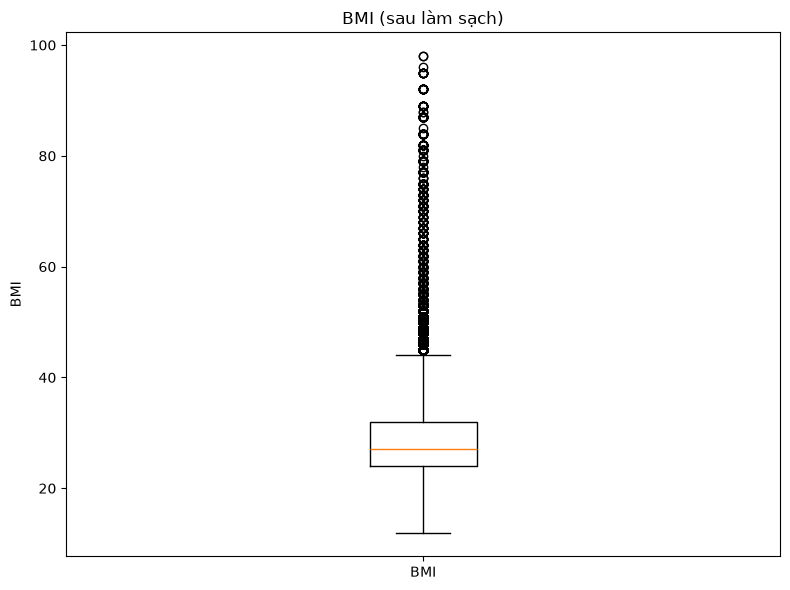

,Chỉ tiêu,Giá trị
0,BMI nhỏ nhất,12
1,BMI lớn nhất,98
2,Ngoài IQR,3379
3,Không khớp phép biến đổi,0
4,Ngoài IQR nhưng khớp nguồn,3379


10 hồ sơ có BMI thấp nhất và 10 hồ sơ có BMI cao nhất ngoài IQR:


,BMI_nguon_x100,BMI_nguon_kg_m2,BMI_sau,Khop_phep_bien_doi,Ngoai_IQR
Index_dong_nguon,,,,,
172552,4453.0,44.53,45,True,True
306130,4453.0,44.53,45,True,True
141890,4455.0,44.55,45,True,True
310020,4455.0,44.55,45,True,True
342642,4455.0,44.55,45,True,True
25083,4456.0,44.56,45,True,True
115899,4459.0,44.59,45,True,True
148117,4459.0,44.59,45,True,True
172970,4459.0,44.59,45,True,True


Kết luận: giữ các giá trị qua kiểm tra; không tự động xóa/chặn theo IQR. Đối chiếu nguồn không xác thực tính chính xác sinh học của câu trả lời.


In [13]:
NON_BINARY=['BMI']
display(iqr_summary(df_clean[NON_BINARY]))
plt.figure(figsize=(8, 6))
plt.boxplot(df_clean['BMI'].dropna())

plt.title('BMI (sau làm sạch)')
plt.ylabel('BMI')
plt.xticks([1], ['BMI'])

plt.tight_layout()
plt.show()
# Đối chiếu BMI ngoài IQR với cùng dòng trong dữ liệu nguồn.
q1, q3 = df_clean['BMI'].quantile([.25, .75])
lo, hi = q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1)
bmi_audit = pd.DataFrame(index=df_clean.index)
bmi_audit['BMI_nguon_x100'] = df_selected_raw.loc[df_clean.index, '_BMI5']
bmi_audit['BMI_nguon_kg_m2'] = bmi_audit['BMI_nguon_x100']/100
bmi_audit['BMI_sau'] = df_clean['BMI']
bmi_audit['Khop_phep_bien_doi'] = bmi_audit['BMI_sau'].eq(bmi_audit['BMI_nguon_kg_m2'].round(0))
bmi_audit['Ngoai_IQR'] = ~bmi_audit['BMI_sau'].between(lo, hi)
extreme_bmi = bmi_audit.loc[bmi_audit['Ngoai_IQR']]
display(pd.DataFrame({
    'Chỉ tiêu': ['BMI nhỏ nhất', 'BMI lớn nhất', 'Ngoài IQR', 'Không khớp phép biến đổi', 'Ngoài IQR nhưng khớp nguồn'],
    'Giá trị': [df_clean.BMI.min(), df_clean.BMI.max(), len(extreme_bmi),
               int((~bmi_audit.Khop_phep_bien_doi).sum()),
               int((bmi_audit.Ngoai_IQR & bmi_audit.Khop_phep_bien_doi).sum())]
}))
assert bmi_audit.Khop_phep_bien_doi.all(), 'Cần kiểm tra lại phép biến đổi BMI.'
print('10 hồ sơ có BMI thấp nhất và 10 hồ sơ có BMI cao nhất ngoài IQR:')
audit_examples = pd.concat([extreme_bmi.nsmallest(10, 'BMI_nguon_kg_m2'),
                            extreme_bmi.nlargest(10, 'BMI_nguon_kg_m2')])
display(audit_examples.rename_axis('Index_dong_nguon'))
print('Kết luận: giữ các giá trị qua kiểm tra; không tự động xóa/chặn theo IQR. Đối chiếu nguồn không xác thực tính chính xác sinh học của câu trả lời.')


### 3.5.2. So sánh phân bố trước/sau làm sạch
**Trước: 187,383 dòng | Sau: 116,662 dòng | Giảm: 37.74%.** So sánh cùng phạm vi 30–59, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.

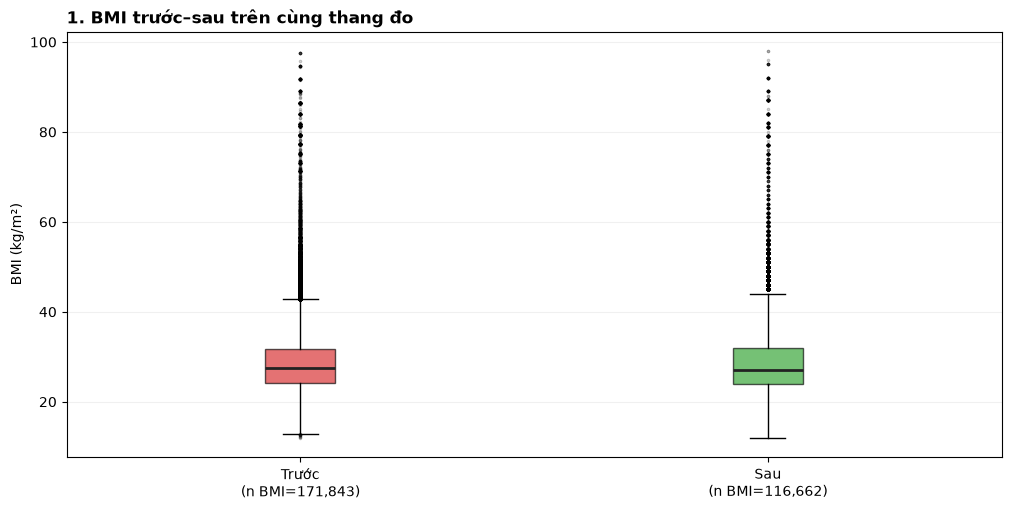

,Trước,Sau
Số BMI không thiếu,171843.00,116662.0
Số NaN,15540.00,0.0
Trung vị,27.40,27.0
Q1,24.13,24.0
Q3,31.62,32.0


BMI trước = _BMI5/100, giữ phần thập phân; BMI sau đã được làm tròn theo quy trình hiện tại. Thay đổi có thể do cả loại dòng và làm tròn.

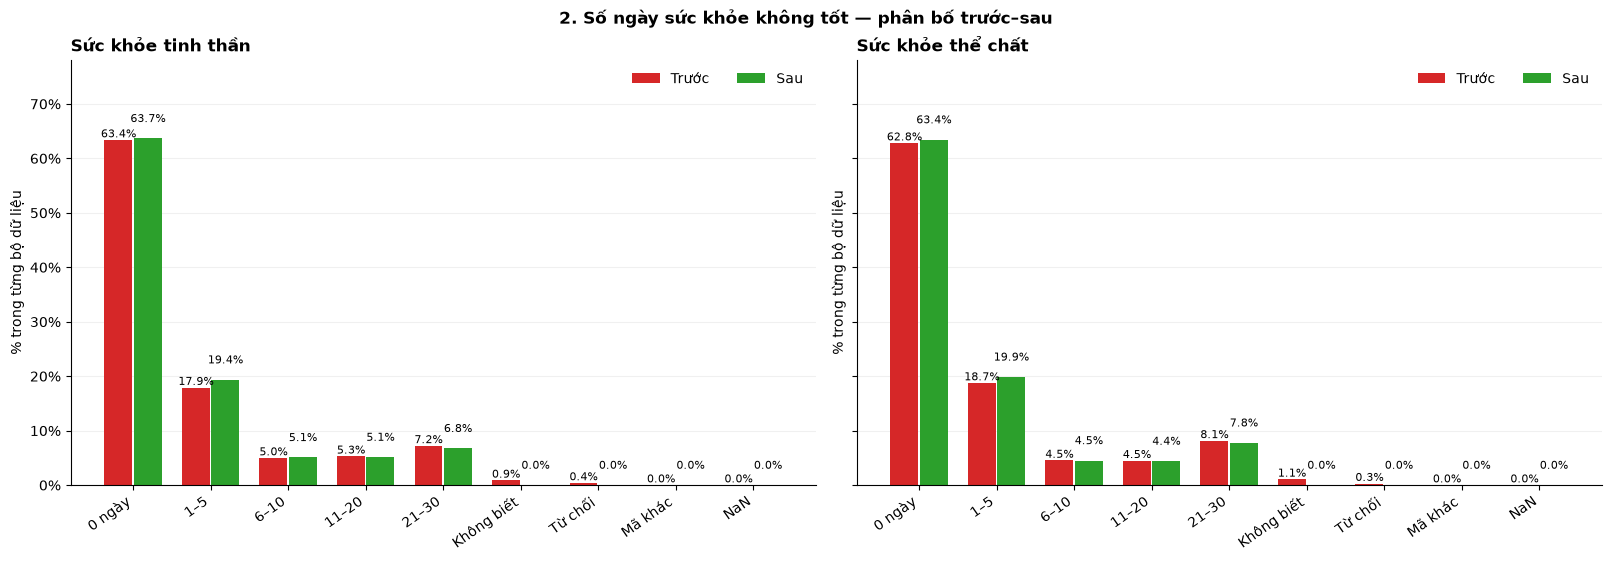

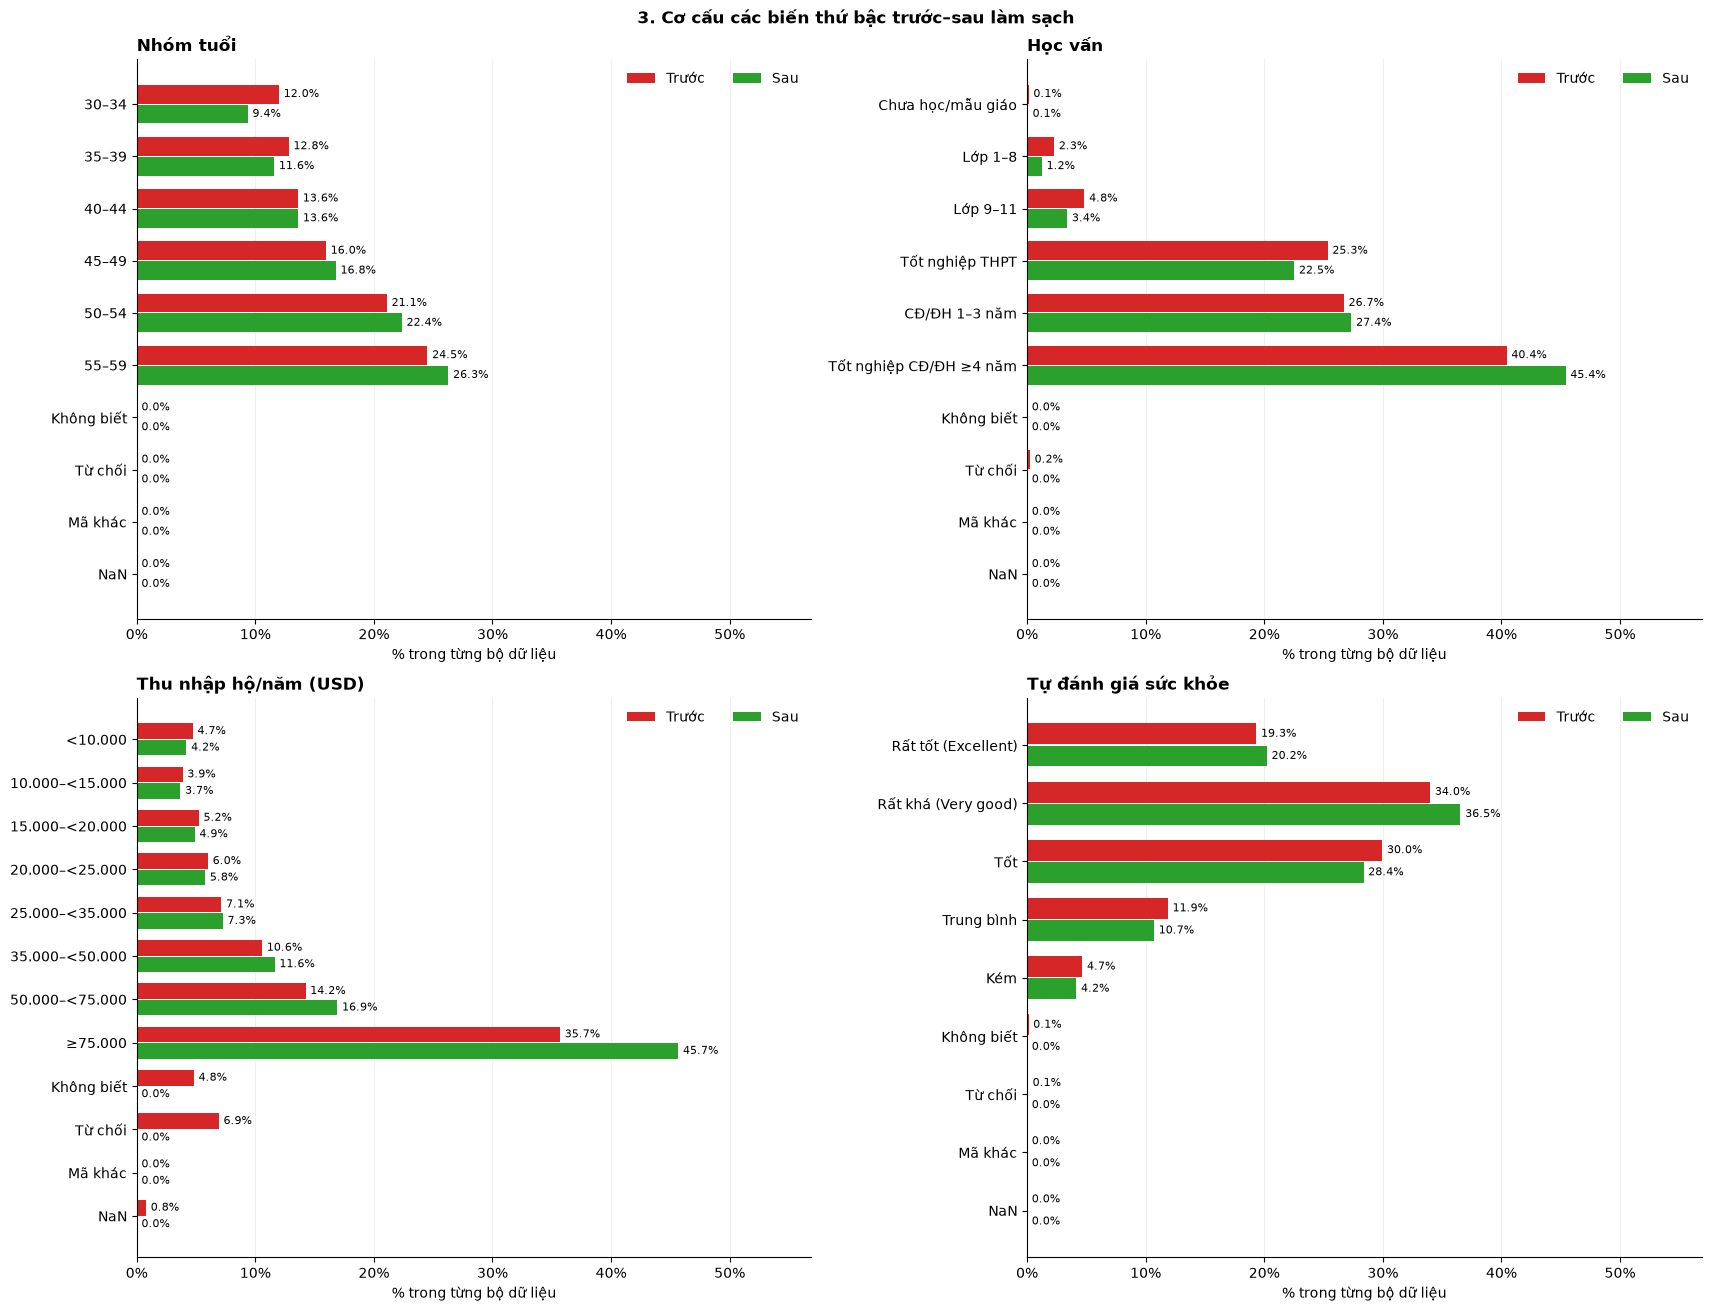

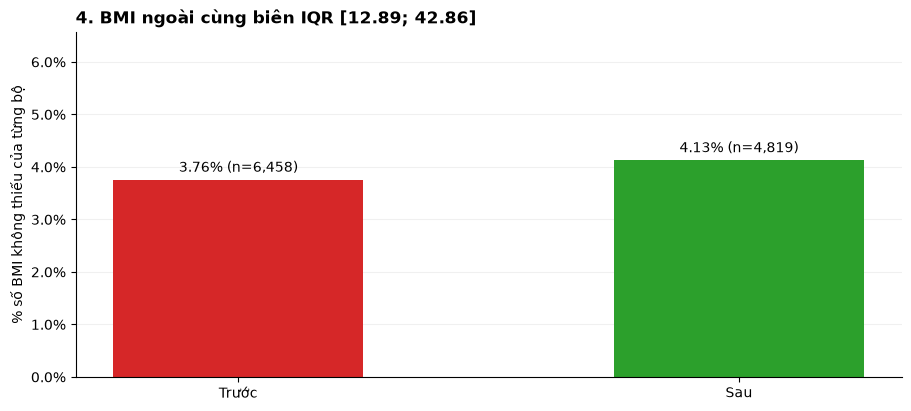

**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. **Không sửa df_selected_raw hoặc df_clean.**

In [14]:
# SO SÁNH PHÂN BỐ TRƯỚC/SAU LÀM SẠCH — MỤC 3.5.2
# Chỉ đọc dữ liệu; đổi đơn vị/nhãn trên bản phục vụ vẽ.
def plot_cleaning_comparison(raw, clean):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from matplotlib.ticker import PercentFormatter
    from IPython.display import display, Markdown

    nb, na = len(raw), len(clean)
    if nb == 0 or na == 0:
        raise ValueError('Cần dữ liệu trước và sau làm sạch có ít nhất một dòng.')
    before_color, after_color = '#D62728', '#2CA02C'
    display(Markdown(
        '### 3.5.2. So sánh phân bố trước/sau làm sạch\n'
        f'**Trước: {nb:,} dòng | Sau: {na:,} dòng | Giảm: {(1-na/nb)*100:.2f}%.** '
        'So sánh cùng phạm vi 30–59, đã loại DIABETE3=2: df_selected_raw với df_clean (bản chính giữ duplicate). '
        'Cột ghép dùng % trong từng bộ, kể cả NaN trong mẫu số; '
        'đỏ = trước, xanh lá cây = sau. Không cân bằng lại mẫu. '
        'Tỷ lệ mô tả file hiện tại, chưa dùng trọng số khảo sát.'))

    def style(ax, horizontal=False):
        ax.set_axisbelow(True)
        ax.grid(axis='x' if horizontal else 'y', alpha=.18)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(PercentFormatter(100))

    def counts(series, mapping, order):
        labels = series.map(mapping).where(series.notna(), 'NaN').fillna('Mã khác')
        return labels.value_counts().reindex(order, fill_value=0)

    def paired(ax, before, after, title, horizontal=False, limit=None):
        x = np.arange(len(before))
        bp, ap = before/nb*100, after/na*100
        if horizontal:
            b = ax.barh(x-.19, bp, height=.36, color=before_color, label='Trước')
            a = ax.barh(x+.19, ap, height=.36, color=after_color, label='Sau')
            ax.set_yticks(x, before.index)
            ax.invert_yaxis()
            ax.set_xlim(0, limit)
            ax.set_xlabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(p+.4, bar.get_y()+bar.get_height()/2,
                            f'{p:.1f}%', va='center', fontsize=8)
        else:
            b = ax.bar(x-.19, bp, width=.36, color=before_color, label='Trước')
            a = ax.bar(x+.19, ap, width=.36, color=after_color, label='Sau')
            ax.set_xticks(x, before.index, rotation=35, ha='right')
            ax.set_ylim(0, limit)
            ax.set_ylabel('% trong từng bộ dữ liệu')
            for bars, ps in [(b, bp), (a, ap)]:
                for bar, p in zip(bars, ps):
                    ax.text(bar.get_x()+bar.get_width()/2, p+(.5 if bars is b else 3),
                            f'{p:.1f}%', ha='center', fontsize=8)
        ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
        ax.legend(frameon=False, ncol=2, loc='upper right')
        style(ax, horizontal)

    with plt.rc_context({'font.family':'DejaVu Sans', 'font.size':10}):
        # 1. BMI cùng đơn vị, toàn bộ giá trị không thiếu, không cắt outlier.
        bmi_before = (raw['_BMI5']/100).dropna()
        bmi_after = clean['BMI'].dropna()
        if bmi_before.empty or bmi_after.empty:
            raise ValueError('BMI không có giá trị quan sát ở một trong hai bộ.')
        fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
        boxes = ax.boxplot([bmi_before, bmi_after], patch_artist=True,
            tick_labels=[f'Trước\n(n BMI={len(bmi_before):,})', f'Sau\n(n BMI={len(bmi_after):,})'],
            flierprops={'marker':'.', 'markersize':3, 'alpha':.25},
            medianprops={'color':'#222222', 'linewidth':2})
        for box, color in zip(boxes['boxes'], [before_color, after_color]):
            box.set_facecolor(color)
            box.set_alpha(.65)
        ax.set_title('1. BMI trước–sau trên cùng thang đo', loc='left', fontweight='bold')
        ax.set_ylabel('BMI (kg/m²)')
        ax.grid(axis='y', alpha=.18)
        plt.show()
        display(pd.DataFrame({
            'Trước': [len(bmi_before), raw['_BMI5'].isna().sum(), bmi_before.median(),
                      bmi_before.quantile(.25), bmi_before.quantile(.75)],
            'Sau': [len(bmi_after), clean['BMI'].isna().sum(), bmi_after.median(),
                    bmi_after.quantile(.25), bmi_after.quantile(.75)]},
            index=['Số BMI không thiếu', 'Số NaN', 'Trung vị', 'Q1', 'Q3']).round(2))
        display(Markdown('BMI trước = _BMI5/100, giữ phần thập phân; BMI sau đã được '
                         'làm tròn theo quy trình hiện tại. Thay đổi có thể do cả loại dòng và làm tròn.'))

        # 2. Số ngày: 88 -> nhãn 0 ngày; 77/99 không phải ngày thực tế.
        day_map = {0:'0 ngày', 88:'0 ngày',
            **{i:'1–5' for i in range(1,6)}, **{i:'6–10' for i in range(6,11)},
            **{i:'11–20' for i in range(11,21)}, **{i:'21–30' for i in range(21,31)},
            77:'Không biết', 99:'Từ chối'}
        day_order = ['0 ngày','1–5','6–10','11–20','21–30','Không biết','Từ chối','Mã khác','NaN']
        day_data = [(counts(raw[r], day_map, day_order), counts(clean[c], day_map, day_order), t)
            for r, c, t in [('MENTHLTH','MentHlth','Sức khỏe tinh thần'),
                            ('PHYSHLTH','PhysHlth','Sức khỏe thể chất')]]
        day_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b, a, _ in day_data)*1.18+3)
        fig, axes = plt.subplots(1,2,figsize=(16,5.5),sharey=True,layout='constrained')
        fig.suptitle('2. Số ngày sức khỏe không tốt — phân bố trước–sau', fontweight='bold')
        for ax, (b,a,t) in zip(axes, day_data):
            paired(ax,b,a,t,limit=day_limit)
        plt.show()

        # 3. Bốn biến thứ bậc: cùng thứ tự nhóm, cùng trục tỷ lệ giữa các ô.
        age = ['30–34','35–39','40–44','45–49','50–54','55–59']
        specs = [
            ('_AGEG5YR','Age','Nhóm tuổi', dict(enumerate(age,3)), {14:'Không biết'}),
            ('EDUCA','Education','Học vấn', {1:'Chưa học/mẫu giáo',2:'Lớp 1–8',3:'Lớp 9–11',
             4:'Tốt nghiệp THPT',5:'CĐ/ĐH 1–3 năm',6:'Tốt nghiệp CĐ/ĐH ≥4 năm'}, {9:'Từ chối'}),
            ('INCOME2','Income','Thu nhập hộ/năm (USD)', {1:'<10.000',2:'10.000–<15.000',
             3:'15.000–<20.000',4:'20.000–<25.000',5:'25.000–<35.000',
             6:'35.000–<50.000',7:'50.000–<75.000',8:'≥75.000'}, {77:'Không biết',99:'Từ chối'}),
            ('GENHLTH','GenHlth','Tự đánh giá sức khỏe', {1:'Rất tốt (Excellent)',
             2:'Rất khá (Very good)',3:'Tốt',4:'Trung bình',5:'Kém'}, {7:'Không biết',9:'Từ chối'})]
        ordinal_data = []
        for r,c,t,valid,special in specs:
            order = list(valid.values()) + ['Không biết','Từ chối','Mã khác','NaN']
            ordinal_data.append((counts(raw[r], {**valid,**special}, order),
                                 counts(clean[c], valid, order), t))
        ord_limit = min(100, max(max(b.max()/nb*100, a.max()/na*100)
                                 for b,a,_ in ordinal_data)*1.18+3)
        fig, axes = plt.subplots(2,2,figsize=(17,13),layout='constrained')
        fig.suptitle('3. Cơ cấu các biến thứ bậc trước–sau làm sạch', fontweight='bold')
        for ax,(b,a,t) in zip(axes.flat,ordinal_data):
            paired(ax,b,a,t,horizontal=True,limit=ord_limit)
        plt.show()

        # 4. BMI ngoài biên: một ngưỡng cố định từ dữ liệu trước đã đổi đơn vị.
        q1,q3 = bmi_before.quantile([.25,.75])
        lo,hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
        out_b = int(((bmi_before<lo)|(bmi_before>hi)).sum())
        out_a = int(((bmi_after<lo)|(bmi_after>hi)).sum())
        percentages = [out_b/len(bmi_before)*100, out_a/len(bmi_after)*100]
        fig, ax = plt.subplots(figsize=(9,4),layout='constrained')
        bars = ax.bar(['Trước','Sau'],percentages,color=[before_color,after_color],width=.5)
        ax.set_ylim(0,max(percentages)*1.35+1)
        for b,p,num in zip(bars,percentages,[out_b,out_a]):
            ax.text(b.get_x()+b.get_width()/2,p+.15,f'{p:.2f}% (n={num:,})',ha='center')
        ax.set_title(f'4. BMI ngoài cùng biên IQR [{lo:.2f}; {hi:.2f}]',loc='left',fontweight='bold')
        ax.set_ylabel('% số BMI không thiếu của từng bộ')
        style(ax)
        plt.show()
        display(Markdown('**Diễn giải:** ngưỡng BMI được tính một lần từ dữ liệu trước, '
            'áp dụng cho cả hai bộ; mẫu số biểu đồ 4 là số BMI không thiếu. '
            'Đây là điểm ngoài biên thống kê, chưa khẳng định là dữ liệu sai. '
            'Nhóm giữ các giá trị qua kiểm tra và đối chiếu nguồn ở mục 3.5.1; không tự động loại theo IQR. '
            'Các mã phản hồi và NaN vẫn được giữ trong biểu đồ trước để thấy tác động làm sạch. '
            '**Không sửa df_selected_raw hoặc df_clean.**'))

plot_cleaning_comparison(df_selected_raw, df_clean)


### 3.5.3. Bảng tổng hợp trước/sau làm sạch

Bảng bên dưới được tính trực tiếp trong lần chạy này. Cột “trước” là mẫu đã chọn tuổi 30–59 và loại DIABETE3=2, chưa xử lý NaN/mã phản hồi. Nhật ký phạm vi, nhật ký làm sạch và bảng này có mẫu số riêng; không gộp loại ngoài phạm vi thành lỗi dữ liệu.

**Biên IQR chung cho dòng so sánh BMI:** Tính một lần từ BMI trước làm sạch sau phép chia 100, chưa làm tròn, rồi áp dụng cho cả hai bộ. Tỷ lệ ngoài biên dùng số BMI không thiếu của từng bộ làm mẫu số.

**Diễn giải:** Thay đổi số lượng và tỷ lệ có thể do loại dòng và làm tròn BMI; không có bước tự động loại theo IQR. Dòng này dùng biên chung [12,895; 42,855], khác với mục 3.5.1 tính biên riêng trên dữ liệu sau làm sạch [12; 44]. Vì vậy, 4.819 điểm ngoài biên chung ở bảng này và 3.379 điểm ngoài biên riêng ở mục 3.5.1 không mâu thuẫn.


In [15]:
summary_comparison = pd.DataFrame({
    'Chỉ tiêu': ['Số dòng', 'Số cột', 'Số ô NaN', 'Dòng chứa NaN',
                'Duplicate ngoài lần đầu', 'Kiểu lưu trữ', 'Mã tuổi', 'Mã nhãn'],
    'Trước clean (đã chọn phạm vi)': [len(df_selected_raw), df_selected_raw.shape[1],
        int(df_selected_raw.isna().sum().sum()), int(df_selected_raw.isna().any(axis=1).sum()),
        int(df_selected_raw.duplicated().sum()), ', '.join(map(str, df_selected_raw.dtypes.unique())),
        '3–8 (30–59 tuổi)', 'DIABETE3: 1/3/4 và mã không rõ/NaN nếu có'],
    'Sau clean (giữ duplicate)': [len(df_clean), df_clean.shape[1],
        int(df_clean.isna().sum().sum()), int(df_clean.isna().any(axis=1).sum()),
        int(df_clean.duplicated().sum()), ', '.join(map(str, df_clean.dtypes.unique())),
        '3–8 (giữ mã gốc)', '0: DIABETE3=3; 1: DIABETE3=1/4']
})
# So sánh BMI theo cùng biên IQR từ dữ liệu trước làm sạch.
# Chỉ đổi thang trên bản phục vụ thống kê; không sửa dữ liệu.
bmi_before_compare = (df_selected_raw['_BMI5'] / 100).dropna()
bmi_after_compare = df_clean['BMI'].dropna()
q1_compare, q3_compare = bmi_before_compare.quantile([.25, .75])
lo_compare = q1_compare - 1.5 * (q3_compare - q1_compare)
hi_compare = q3_compare + 1.5 * (q3_compare - q1_compare)
outside_before_compare = int((~bmi_before_compare.between(lo_compare, hi_compare)).sum())
outside_after_compare = int((~bmi_after_compare.between(lo_compare, hi_compare)).sum())

def outlier_comparison_text(count, total):
    number = f'{count:,}'.replace(',', '.')
    percent = f'{count / total * 100:.2f}'.replace('.', ',')
    return f'{number} — {percent}%'

summary_comparison = pd.concat([
    summary_comparison,
    pd.DataFrame({
        'Chỉ tiêu': ['Biểu diễn BMI', 'Mã khảo sát đặc biệt', 'BMI ngoài cùng biên IQR'],
        'Trước clean (đã chọn phạm vi)': [
            'Giá trị nguồn nhân 100',
            'Còn mã không biết/từ chối và mã 88 ở biến số ngày',
            outlier_comparison_text(outside_before_compare, len(bmi_before_compare))],
        'Sau clean (giữ duplicate)': [
            'Chia 100 và làm tròn',
            'Loại mã cần loại; chuyển 88 thành 0 ngày',
            outlier_comparison_text(outside_after_compare, len(bmi_after_compare))]
    })
], ignore_index=True)

display(summary_comparison)
print(f'Mẫu trước clean: {len(df_selected_raw):,}; sau clean: {len(df_clean):,}; '
      f'loại do làm sạch: {len(df_selected_raw)-len(df_clean):,} '
      f'({(1-len(df_clean)/len(df_selected_raw))*100:.2f}%).')
print(f'Bản đối chiếu không duplicate: {len(df_no_duplicates):,} dòng.')
assert len(df_selected_raw) - sum(row[2] for row in audit_rows) == len(df_clean)


,Chỉ tiêu,Trước clean (đã chọn phạm vi),Sau clean (giữ duplicate)
0,Số dòng,187383,116662
1,Số cột,22,22
2,Số ô NaN,55113,0
3,Dòng chứa NaN,41805,0
4,Duplicate ngoài lần đầu,4385,13836
5,Kiểu lưu trữ,float64,int16
6,Mã tuổi,3–8 (30–59 tuổi),3–8 (giữ mã gốc)
7,Mã nhãn,DIABETE3: 1/3/4 và mã không rõ/NaN nếu có,0: DIABETE3=3; 1: DIABETE3=1/4
8,Biểu diễn BMI,Giá trị nguồn nhân 100,Chia 100 và làm tròn
9,Mã khảo sát đặc biệt,Còn mã không biết/từ chối và mã 88 ở biến số ngày,Loại mã cần loại; chuyển 88 thành 0 ngày


Mẫu trước clean: 187,383; sau clean: 116,662; loại do làm sạch: 70,721 (37.74%).
Bản đối chiếu không duplicate: 102,826 dòng.


# PART 4: CONCLUSION & NEXT STEPS [1.0 POINT]

### Key Guidelines:
1. **Mức độ sẵn sàng:** Đánh giá dữ liệu đã sẵn sàng cho phân tích chuyên sâu hay chưa.
2. **Kế hoạch báo cáo giai đoạn 2:** Nêu các bước EDA và chuẩn bị feature tiếp theo.

---


#### STUDENT TASK 4.1: DATA READINESS ASSESSMENT & NEXT STEPS

**Tổng hợp lần chạy:** Từ 441.456 hồ sơ nguồn, chọn 189.770 hồ sơ 30–59 tuổi và loại 2.387 hồ sơ DIABETE3=2, còn 187.383 hồ sơ trước clean. Đầu ra chính có 116.662 dòng × 22 cột; lớp 1 chiếm 10,92%. Bản đối chiếu không duplicate có 102.826 dòng.

**Mức độ sẵn sàng:** Dữ liệu sau làm sạch giữ đủ 21 feature và một nhãn, kiểm tra NaN/giá trị không hữu hạn/miền giá trị và ép kiểu không đổi giá trị. Số dòng, tỷ lệ lớp và duplicate nằm ở các bảng kết quả thực thi. Age chỉ còn mã 3–8; không có hồ sơ nguồn DIABETE3=2. Giữ duplicate trong bản chính, tạo bản không duplicate để đối chiếu. BMI được làm tròn và các điểm ngoài IQR qua kiểm tra vẫn được giữ như cách làm hiện tại.

**Giới hạn:** Chọn tuổi và loại tiểu đường khi mang thai xác định phạm vi nghiên cứu. Xóa NaN/mã phản hồi tiếp tục làm giảm mẫu; missing cấu trúc ở câu hỏi cholesterol có thể gây thiên lệch lựa chọn. Không dùng trọng số khảo sát để suy rộng. Kết luận chỉ dành cho mẫu sau xử lý, không suy diễn nhân quả, hiệu quả chẩn đoán hoặc dự đoán phát bệnh tương lai. 21 feature là bộ ứng viên kế thừa, chưa phải tập tối ưu.

**Ongoing 2:** EDA trong mẫu mới, xem phân bố nhãn và các feature, khảo sát liên hệ với nhãn, lựa chọn preprocessing và chạy thử mô hình. Các biến đang giữ nguyên; không mặc định loại năm biến trong kế hoạch cũ. Khi chia dữ liệu, xem xét duplicate trên 21 feature và rò rỉ giữa các phần; fit preprocessing/cân bằng mẫu chỉ trên dữ liệu huấn luyện. So sánh mô hình bằng các chỉ số đã xác định, chưa khẳng định thu hẹp tuổi sẽ cải thiện kết quả.

**Ongoing 3:** Fine tuning, lựa chọn cấu hình/ngưỡng và đánh giá cuối cùng theo thiết kế phù hợp. Các bước mô hình không thực hiện trong ongoing 1.


## Xuất dữ liệu và nhật ký

Thư mục riêng `data_age30_59_no_gestational` chứa hai CSV 22 cột, không lưu index: `cleaned_cdc2015_keep_duplicates.csv` (bản chính) và `cleaned_cdc2015_no_duplicates.csv` (đối chiếu).

Đọc lại CSV và đối chiếu giá trị/kiểu dữ liệu. Lưu `cohort_audit.csv`, `cleaning_audit.csv`, `cleaning_summary.csv` và `dataset_metadata.json` để nhận diện quần thể, phiên bản nhãn, số lượng/tỷ lệ lớp và quy tắc làm sạch. Các số liệu của bản toàn tuổi/nhãn cũ không được tái sử dụng cho phạm vi này.

Giai đoạn này chưa chuẩn hóa thang đo, encoding bổ sung, chọn feature, tái cân bằng mẫu hoặc chạy mô hình.


In [16]:
from pathlib import Path

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

datasets = {
    "cleaned_cdc2015_keep_duplicates.csv": df_clean,
    "cleaned_cdc2015_no_duplicates.csv": df_no_duplicates
}

for filename, frame in datasets.items():
    output_path = OUTPUT_DIR / filename
    frame.to_csv(output_path, index=False)

    reloaded = pd.read_csv(
    output_path,
    dtype=frame.dtypes.to_dict()
)
    pd.testing.assert_frame_equal(
        frame.reset_index(drop=True),
        reloaded
    )

    print(
        f"{filename}: {len(reloaded):,} dòng, "
        f"{reloaded.shape[1]} cột — đối chiếu thành công"
    )

print("Thư mục xuất:", OUTPUT_DIR.resolve())

import json
metadata = {
    'source': 'CDC BRFSS2015 LLCP2015XPT.zip',
    'target': 'Diabetes_binary',
    'target_mapping': {'1': 1, '3': 0, '4': 1},
    'excluded_target_codes': [2, 7, 9],
    'version': 'brfss2015_age30_59_gestational_excluded_v1',
    'note': 'Academic classification of self-reported survey labels; no future-onset prediction.',
    'population': {'age_years_inclusive': [30, 59], 'source_age_column': '_AGEG5YR',
                   'allowed_age_codes': list(range(3, 9)), 'employment_filter': None,
                   'gestational_only_diabetes': 'exclude rows DIABETE3=2 before target recoding'},
    'feature_names': df_clean.columns.drop('Diabetes_binary').tolist(),
    'feature_count': 21,
    'processing': {'missing': 'dropna on all 22 selected columns',
                   'survey_codes': 'same removal/recoding rules as input notebook, except DIABETE3=2 excluded',
                   'bmi': 'divide by 100 and round to integer',
                   'outliers': 'retain values passing existing checks; no IQR deletion/capping',
                   'dtypes': 'int16', 'duplicate_main': 'keep',
                   'duplicate_comparison': 'drop_duplicates on all 22 columns',
                   'survey_weighted': False, 'modeling_performed': False},
    'cohort_flow': cohort_audit.to_dict(orient='records'),
    'cleaning_flow': pd.DataFrame(audit_rows, columns=['step','before','removed','after']).to_dict(orient='records'),
    'validation': {'source_label_mapping_verified': True, 'csv_roundtrip_verified': True,
                   'missing_cells_after': int(df_clean.isna().sum().sum()),
                   'domain_errors': int(total_errors)},
    'bmi_iqr': {'lower': float(lo), 'upper': float(hi),
                 'outside_count': len(extreme_bmi),
                 'outside_percent': len(extreme_bmi)/len(df_clean)*100},
    'datasets': {name: {'rows': len(frame), 'columns': len(frame.columns),
                        'duplicate_rows': int(frame.duplicated().sum()),
                        'class_counts': {str(k): int(v) for k, v in frame.Diabetes_binary.value_counts().items()},
                        'class_percent': {str(k): float(v*100) for k, v in frame.Diabetes_binary.value_counts(normalize=True).items()}}
                 for name, frame in datasets.items()}
}
(OUTPUT_DIR/'dataset_metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu metadata nhận diện phiên bản nhãn.')

cohort_audit.to_csv(AUDIT_DIR/'cohort_audit.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(audit_rows, columns=['step','before','removed','after']).to_csv(
    AUDIT_DIR/'cleaning_audit.csv', index=False, encoding='utf-8-sig')
summary_comparison.to_csv(AUDIT_DIR/'cleaning_summary.csv', index=False, encoding='utf-8-sig')
assert df_no_duplicates.duplicated().sum() == 0
pd.testing.assert_frame_equal(df_no_duplicates, df_clean.drop_duplicates())
print('Đã lưu nhật ký chọn phạm vi, làm sạch và bảng tổng hợp.')


cleaned_cdc2015_keep_duplicates.csv: 116,662 dòng, 22 cột — đối chiếu thành công
cleaned_cdc2015_no_duplicates.csv: 102,826 dòng, 22 cột — đối chiếu thành công
Thư mục xuất: C:\Users\Admin\Documents\Codex\2026-10-16\ba\outputs\data_age30_59_no_gestational
Đã lưu metadata nhận diện phiên bản nhãn.
Đã lưu nhật ký chọn phạm vi, làm sạch và bảng tổng hợp.


## Tài liệu tham khảo

- [CDC BRFSS2015](https://www.cdc.gov/brfss/annual_data/annual_2015.html) và [BRFSS2015 Codebook](https://www.cdc.gov/brfss/annual_data/2015/pdf/CODEBOOK15_LLCP.pdf): nguồn dữ liệu, nội dung câu hỏi, mã phản hồi và nhánh câu hỏi.
- [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) và [notebook Alex Teboul](https://www.kaggle.com/code/alexteboul/diabetes-health-indicators-dataset-notebook): căn cứ kế thừa bộ 21 feature và phần lớn quy trình xử lý. Bản này chọn tuổi 30–59, loại hồ sơ chỉ tiểu đường khi mang thai, và gộp tiền tiểu đường/tiểu đường thành lớp 1 theo định nghĩa nghiên cứu.
- Các nghiên cứu và nguồn chuyên ngành được dẫn trực tiếp trong bảng căn cứ chọn biến. Nhóm xem xét khác biệt về quần thể, năm khảo sát, nhãn và cách đo khi sử dụng kết quả tham khảo.
